# GKD student HP exploration — Stage A of `20260809_breadth4_160m`

End-to-end analysis of **Stage A** (student HP screen A1, control floor A2,
dose ladder A3, and the recipe freeze) for the finished four-animal on-policy
GKD campaign on PolyPythia-160M. Animals, β, LoRA grid, doses, and freeze
doses come from `subliminal_learning.campaign.breadth_plan` — this notebook
does not re-state those literals.

This is the four-animal successor to `notebooks/gkd_student_hp_exploration.ipynb`
(an earlier two-animal run). β is reverse-KL only. Storytelling is a new
Cloud-parity sample-scored set. In-training probes include **step 0**.

This notebook is **read-only** on `output_root`. It does not train, does not
write under the SSD, and does not save figures unless you change that. Paths
resolve from `configs/paths/paths_local.yaml` via `analysis.setup.bootstrap`.

**Scientific frame (in scope).** (L0) is on-policy GKD subliminal learning real
against a matched base-teacher control? (L1) does it hold across four animals
rather than two? (L3) is the HP surface / freeze stable when the freeze is a
four-animal intersection? (L4) does the storytelling OOD set agree with the
`test` prob delta?

**Run from the repo root:**
```bash
uv sync
uv run jupyter lab
```
Open `notebooks/gkd_breadth4_student_hp_exploration.ipynb` and run all cells
top-to-bottom.

### Reading guide — aggregation rules

- **Never re-average** `p_target` / `p_target_mean` / `subliminal_delta` as if
  they were leaves. `subliminal_delta` already collapsed teacher ftseed.
- **Never pool raw `p_target` across animals.** Control floors differ by tens
  of times; work in matched-control deltas or z-score within animal.
- **A1 is single-gseed by design.** Do not treat the HP screen as multi-seed
  evidence.
- **Probe metrics are not eval-grade.** Screening uses `training_metrics.jsonl`;
  claims use `preference_summary.json` + `subliminal_delta_ci`.
- **Keep `teacher_cross_init` when joining deltas.** Same-init (`tfs0`) and
  cross (`tfs0_tbase-weight-seed1`) share a `gkd_tag` but are different cells.
- **Filter `~diverged` yourself** before `end_of_run_probes` / `peak_probes`.
  Neither reducer drops diverged leaves.
- **`delta_vs_base` is not the Cloud effect.** It compares to the untuned base
  LM, not the GKD control.
- **Do not pool `storytelling` into the `test` headline.** It is `sample`-scored
  and was excluded from the freeze (which requires `scoring=="prob"`).
- **`ft_seeds` on preference summaries are student gseeds**, not teacher ftseeds.
- **`run_set.json` `launches` are not per-cell cards** (more leaves than
  launches). Coverage is a filesystem walk. `grid_axes` is a union across
  stages — not an A1-only grid.
- Rankings in this notebook are **post-hoc**. No formal Stage-B pre-registration
  file was filed.

### What this notebook covers

| § | Topic |
|---|---|
| 0 | Provenance and campaign cost |
| 1 | Inventory and coverage audit |
| 2 | Control floor per animal |
| 3 | HP surface per animal |
| 4 | Cross-animal consistency of the HP surface |
| 5 | Is there an lr × α law? |
| 6 | Divergence and instability map |
| 7 | Dose ladder |
| 8 | A3 `ref` arm as a cross-animal HP-transfer test |
| 9 | Emergence timing (step 0 present) |
| 10 | Same-init vs cross arm |
| 11 | Eval-grade confirmation |
| 12 | Prompt-set generalization, including storytelling |
| 13 | Forced-choice specificity (4×4 off-target) |
| 14 | Capability guardrail (PPL + lm-eval where present) |
| 15 | Teacher strength as covariate |
| 16 | Seed-noise decomposition |
| 17 | Freeze reconciliation (compromise, not per-animal optimum) |
| 18 | Takeaways, claims, how to extend |

### Explicit exclusions

- Project hypotheses **H1 / H2** (batch-composition vs weight-init pairings;
  init-independent vocabulary geometry). Re-litigating them is out of scope.
- β = 0 / forward-KL; seed depth beyond three gseeds; model-size sweeps.
- Stage C (λ / vocab_mask / full-FT teacher); Stage B factorial write-up
  (a sibling notebook); CKA / EAS / steering.
- Random-teacher / shuffle / ICL negatives; PolyPythia seeds 1–9 as a sweep.
- Do not cite a non-existent `docs/CAMPAIGN_RESULTS_SLBREADTH.md`.

### Metric cheat-sheet

| ID | Answers | Values | How scored | Notes |
|---|---|---|---|---|
| `p_target` (`test` / `prob`) | Does the student put mass on the leading-space animal token? | [0, 1] | Mean over prompts of last-token p(`" {animal}"`) | Headline set. Not comparable across animals. |
| `subliminal_delta` | Did GKD from a biased teacher raise `p_target` above a matched **base-teacher** control? | difference of two probabilities | `p_target_treatment − p_target_control`; treatments averaged over teacher ftseed within lineage | Cloud SL effect. Never re-average over ftseed; never pool animals. |
| `subliminal_delta_ci` | Same effect with a paired-gseed interval | mean + t-interval | Mean each gseed across tfs, pair to the control's matching gseed | Use this for CIs, not the marginal `ci_lower`/`ci_upper` on preference rows. |
| control floor | How high is a student distilled from an **unfinetuned** teacher at the same recipe? | [0, 1] | Control leaf `p_target` | Not a no-training baseline. A2 gate: max and spread thresholds from the plan. |
| dose `e` | How many passes over the fixed prompt pool? | `A3_DOSES` from the plan (printed in Setup) | Each dose is a complete run with its own schedule | Not a truncation of a longer run. |
| β / λ | What GKD mix / on-policy fraction? | reverse KL (mode-seeking); fully on-policy student generation | `gkd_tag`; values printed in Setup | This campaign does not sweep β. |
| tfs vs gseed | Which RNG axis? | integers | Teacher ftseed vs student generation seed | Independent. Preference `ft_seeds` are gseeds. |
| PolyPythia inits | Which base? | `original` / `pythia-160m` (seed 0); `data-seed{1,2,3}`; `weight-seed{1,2,3}` | Hub repo dir name | Loader `teacher_base_label` spells seed-0 as `full-seed0`; `short_model()` says `original`. |
| `storytelling` | Does the trait appear in sampled open-ended text? | [0, 1] hit rate | `scoring=sample` (n_samples / temperature / max_new_tokens from the summary) | Rank fields are JSON null by design. New vs the earlier campaign. |
| FC `target_share` | Is the preference specific among 10 animals? | [0, 1] | Softmax over the candidate roster | All four campaign animals are in the roster — off-target leakage is measurable. |
| `perplexity_ratio` | Is it still a language model vs its own base? | (0, ∞); 1 = unchanged | Pile PPL / base PPL | Apply a finite mask before any mean. Missing `benchmarks` is expected. |


## Setup


In [1]:
from __future__ import annotations

import json
import math
import re
import sys
from datetime import datetime
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from scipy.stats import spearmanr

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis import stats as astats
from subliminal_learning.analysis.frames import add_lora_label, print_scope, short_model
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.campaign.breadth_plan import (
    A1_GSEEDS,
    A1_LORA_LRS,
    A1_SELECTION_REPORT,
    A1_STUDENT_MODES,
    A2_STUDENT_MODE,
    A3_DOSES,
    A3_GSEEDS,
    A3_MAX_SAME_ARMS,
    A3_REFERENCE_RECIPE,
    A3_TOP_K,
    ANIMALS,
    BETAS,
    CALIBRATION_REPORT,
    CAMPAIGN_DONE_FILE,
    CAMPAIGN_STATE_FILE,
    CONTROL_FLOOR_MAX,
    CONTROL_FLOOR_MAX_SPREAD,
    CONTROL_LOG_FILE,
    EVAL_PROMPT_SETS,
    FREEZE_DOSES,
    FREEZE_REPORT,
    INIT_EQUALITY_REPORT,
    LMBDA,
    Q_A1,
    Q_A1_EVALS,
    Q_A2,
    Q_A3,
    Q_A3_EVALS,
    Q_TEACHER_T1,
    Q_TEACHER_T1_EVALS,
    Q_TEACHER_T2,
    Q_TEACHER_T2_EVALS,
    RUN_SET_ID,
    TEACHER_PARAM_TAG_LORA,
    TEACHER_RUN_SET_ID,
)
from subliminal_learning.campaign.selection import (
    Recipe,
    end_of_run_probes,
    freeze_recipes,
    peak_probes,
)
from subliminal_learning.config import LoRAConfig
from subliminal_learning.evaluation.gkd_results_io import (
    DIVERGENCE_PPL_FACTOR,
    load_gkd_capability_results,
    load_gkd_forced_choice_results,
    load_gkd_preference_results,
    load_gkd_probe_trajectories,
    parse_gkd_tag,
    parse_teacher_tag,
    subliminal_delta,
    subliminal_delta_ci,
    subliminal_delta_sign_test,
)
from subliminal_learning.evaluation.preference_scoring import sign_test
from subliminal_learning.evaluation.sdf_results_io import load_sdf_preference_results
from subliminal_learning.gkd.layout import gkd_tag

ROOT, OUTPUT_ROOT = bootstrap()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

SUBDIR = f"gkd_students/{RUN_SET_ID}"
TREE = OUTPUT_ROOT / SUBDIR
TEACHER_SUBDIR = f"sdf_teachers/{TEACHER_RUN_SET_ID}"
STAGE_A_STUDENT = "pythia-160m-data-seed1"
TEACHER_PREFIX = f"sdf-{TEACHER_PARAM_TAG_LORA}-tfs0"
SAME_TEACHER_TAG = TEACHER_PREFIX
CROSS_TEACHER_TAG = f"{TEACHER_PREFIX}_tbase-weight-seed1"
CROSS_BASE_LABEL = "weight-seed1"
LR_EDGE = 8.0e-4
PROB_SETS = tuple(s for s in EVAL_PROMPT_SETS if s != "storytelling")
SET_ORDER = list(EVAL_PROMPT_SETS)
ANIMAL_COLORS = {a: f"C{i}" for i, a in enumerate(ANIMALS)}
DEEP_ANIMAL = "bear"
BOOTSTRAP_SEED = 20260805
PROMPT_SETS = list(EVAL_PROMPT_SETS)

FROZEN_GKD_TAG = gkd_tag(
    lmbda=float(LMBDA),
    beta=1.0,
    student_mode="lora",
    learning_rate=float(A3_REFERENCE_RECIPE.lr),
    num_epochs=1.0,
    lora=LoRAConfig(
        r=int(A3_REFERENCE_RECIPE.lora_r),
        lora_alpha=int(A3_REFERENCE_RECIPE.lora_alpha),
        lora_dropout=0.0,
        target_modules="all-linear",
    ),
)
A2_RA = tuple(int(x) for x in re.match(r"lora-r(\d+)a(\d+)$", A2_STUDENT_MODE).groups())
A1_RA = tuple(
    tuple(int(x) for x in re.match(r"lora-r(\d+)a(\d+)$", m).groups())
    for m in A1_STUDENT_MODES
)
T2_DESIGNED_TAGS = tuple(
    f"ep{e}_lr{lr}_r{r}a{r}"
    for e in (1, 3, 5)
    for lr in ("3.5e-5", "5e-5")
    for r in (64, 128)
)

set_plot_style()
plt.rcParams.update({"figure.max_open_warning": 50})


def _isclose_any(value: float, options: tuple[float, ...]) -> bool:
    return any(math.isclose(float(value), float(x)) for x in options)


def mode_token(r, a) -> str:
    return f"lora-r{int(r)}a{int(a)}"


def is_stage_a_teacher(tag: str) -> bool:
    return tag in (SAME_TEACHER_TAG, CROSS_TEACHER_TAG)


def with_lora_label(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["lora_r"] = out["student_lora_r"]
    out["lora_alpha"] = out["student_lora_alpha"]
    return add_lora_label(out)


def healthy(df: pd.DataFrame) -> pd.DataFrame:
    if "diverged" not in df.columns:
        return df.copy()
    return df[~df["diverged"]].copy()


def same_init(df: pd.DataFrame) -> pd.DataFrame:
    if "teacher_cross_init" in df.columns:
        return df[~df["is_control"] & ~df["teacher_cross_init"].fillna(False).astype(bool)].copy()
    return df[~df["is_control"] & df["teacher_base_label"].isna()].copy()


def cross_arm(df: pd.DataFrame) -> pd.DataFrame:
    if "teacher_cross_init" in df.columns:
        return df[
            ~df["is_control"]
            & df["teacher_cross_init"].fillna(False).astype(bool)
            & (df["teacher_base_label"] == CROSS_BASE_LABEL)
        ].copy()
    return df[~df["is_control"] & (df["teacher_base_label"] == CROSS_BASE_LABEL)].copy()


def in_a1_recipe(r, a, lr) -> bool:
    return (int(r), int(a)) in A1_RA and _isclose_any(lr, A1_LORA_LRS)


def is_a2_official_row(row: pd.Series) -> bool:
    # Leaf frames mark controls with ``kind``; eval frames use ``is_control``.
    return bool(
        (bool(row.get("is_control", False)) or row.get("kind") == "control")
        and row.get("model") == STAGE_A_STUDENT
        and int(row["student_lora_r"]) == A2_RA[0]
        and int(row["student_lora_alpha"]) == A2_RA[1]
        and _isclose_any(row["student_lr"], A1_LORA_LRS)
        and math.isclose(float(row["num_epochs"]), 1.0)
        and int(row.get("gseed", 0)) == 0
    )


def recipe_key(r, a, lr) -> tuple[int, int, float]:
    return (int(r), int(a), float(lr))


def recipe_label(r, a, lr) -> str:
    return f"r{int(r)}a{int(a)}@{float(lr):.0e}"


def animal_grid(n: int = 4, figsize=(11, 8), **kwargs):
    fig, axes = plt.subplots(2, 2, figsize=figsize, **kwargs)
    return fig, axes.ravel()


def parse_iso(ts: str) -> datetime:
    return datetime.fromisoformat(ts.replace("Z", "+00:00"))


assert TREE.exists(), f"expected run tree missing: {TREE}"
assert list(BETAS) == [1.0], BETAS
assert FROZEN_GKD_TAG == "lmb1.0_b1.0_lora_lr4e-4_e1_r8a16", FROZEN_GKD_TAG
print("output_root :", OUTPUT_ROOT)
print("subdir      :", SUBDIR)
print("tree        :", TREE)
print("teacher_sub :", TEACHER_SUBDIR)
print("animals     :", ANIMALS)
print("betas       :", BETAS, "lmbda", LMBDA)
print("frozen tag  :", FROZEN_GKD_TAG)
print("eval sets   :", EVAL_PROMPT_SETS)
print("DEEP_ANIMAL :", DEEP_ANIMAL, "BOOTSTRAP_SEED", BOOTSTRAP_SEED)
print("Setup OK.")


output_root : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning
subdir      : gkd_students/20260809_breadth4_160m
tree        : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260809_breadth4_160m
teacher_sub : sdf_teachers/20260809_breadth4-teachers_160m
animals     : ('cat', 'dog', 'bear', 'eagle')
betas       : (1.0,) lmbda 1.0
frozen tag  : lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
eval sets   : ('test', 'favorite', 'dislike', 'validation', 'consensus', 'register', 'storytelling')
DEEP_ANIMAL : bear BOOTSTRAP_SEED 20260805
Setup OK.


In [2]:
print("Loading preference / FC / capability (eval-grade)...")
pref_all = load_gkd_preference_results(OUTPUT_ROOT, SUBDIR, animals=list(ANIMALS))
fc_all = load_gkd_forced_choice_results(OUTPUT_ROOT, SUBDIR, animals=list(ANIMALS))
cap_all = load_gkd_capability_results(OUTPUT_ROOT, SUBDIR, animals=list(ANIMALS))
print(f"  pref_all={len(pref_all)}  fc_all={len(fc_all)}  cap_all={len(cap_all)}")

print("Loading probe trajectories (this can take a minute)...")
probes_all = load_gkd_probe_trajectories(OUTPUT_ROOT, SUBDIR, animals=list(ANIMALS))
print(
    f"  probes_all: {len(probes_all)} rows, "
    f"{probes_all['run_dir'].nunique()} leaves"
)

assert not pref_all.empty and not probes_all.empty
print("Load complete.")


Loading preference / FC / capability (eval-grade)...


  pref_all=4319  fc_all=6170  cap_all=617
Loading probe trajectories (this can take a minute)...


  probes_all: 48175 rows, 1305 leaves
Load complete.


## 0. Provenance and campaign cost

**What this measures.** Run-set pin, teacher run-set, finish stamp, driver
transitions, A0 init-equality (the premise that licenses shared-init labels),
packing calibration, pause/resume events, and optional job-queue telemetry
(jobs / requeues / GPU-hours). Queue telemetry is outside the run-set tree
and is read defensively.


In [3]:
run_set = json.loads((TREE / "run_set.json").read_text())
campaign_done = (TREE / "logs" / CAMPAIGN_DONE_FILE).read_text().strip()
calib = json.loads((TREE / "logs" / CALIBRATION_REPORT).read_text())
init_eq = json.loads((TREE / "logs" / INIT_EQUALITY_REPORT).read_text())
freeze = json.loads((TREE / "logs" / FREEZE_REPORT).read_text())
a1_sel = json.loads((TREE / "logs" / A1_SELECTION_REPORT).read_text())
camp_state = json.loads((TREE / "logs" / CAMPAIGN_STATE_FILE).read_text())
ctrl_log_path = TREE / "logs" / CONTROL_LOG_FILE

print("run_set_id         :", run_set.get("run_set_id"))
print("run_type           :", run_set.get("run_type"))
print("purpose            :", run_set.get("purpose"))
print("date / owner       :", run_set.get("date"), run_set.get("owner"))
print("teacher_run_set_id :", run_set.get("teacher_run_set_id"))
print("model_size         :", run_set.get("model_size"))
print("git_sha            :", run_set.get("git_sha"))
print("sweep_yaml         :", run_set.get("sweep_yaml"))
print("top-level keys     :", sorted(run_set.keys()))
print("n launches         :", len(run_set.get("launches") or []))
launch_shas = {ln.get("git_sha") for ln in (run_set.get("launches") or [])}
print("unique launch git_sha:", launch_shas)
assert run_set.get("run_set_id") == RUN_SET_ID
assert run_set.get("teacher_run_set_id") == TEACHER_RUN_SET_ID
assert run_set.get("git_sha") == "3774afdede24066435c8e09e6918962b6c1b2da3"
assert launch_shas == {run_set.get("git_sha")}
print("grid_axes keys (union across stages, not A1-only):",
      sorted((run_set.get("grid_axes") or {}).keys()))
if "num_epochs" in (run_set.get("grid_axes") or {}):
    print("  grid_axes.num_epochs:", run_set["grid_axes"]["num_epochs"])

print()
print("CAMPAIGN_DONE:", campaign_done)
transitions = camp_state.get("transitions", {})
print("campaign_state transitions:")
for name in ("submit_initial", "submit_a3", "submit_b", "finalize"):
    meta = transitions.get(name) or {}
    print(f"  {name}: at={meta.get('at')}")

print()
print("init_equality revision:", init_eq.get("revision"),
      "verdict:", init_eq.get("verdict"))
assert init_eq.get("verdict") == "as_expected"
for pair in init_eq.get("pairs") or []:
    a, b = pair["pair"]
    print(
        f"  {a} vs {b}: equal={pair['equal']} "
        f"mismatched={pair['n_mismatched']}/{pair['n_tensors']} "
        f"as_expected={pair['as_expected']}"
    )

print()
print("calibration recommended_cap_per_gpu:", calib.get("recommended_cap_per_gpu"))
for k, v in sorted((calib.get("per_concurrency") or {}).items(), key=lambda x: int(x[0])):
    print(f"  concurrency={k}: s_per_it={v.get('s_per_it')}")

print()
winner = freeze.get("winner") or (freeze.get("frozen") or {}).get("1") or {}
print("freeze headline_beta:", freeze.get("headline_beta"))
print("freeze_doses:", freeze.get("freeze_doses"), "plan FREEZE_DOSES:", FREEZE_DOSES)
print("winner recipe:", winner.get("recipe"), "e=", winner.get("num_epochs"))
print("winner cross-animal Δ:", winner.get("subliminal_delta"))
print("winner per_animal:", winner.get("per_animal_delta"))
assert math.isclose(float(freeze.get("headline_beta")), 1.0)
assert list(freeze.get("freeze_doses")) == list(FREEZE_DOSES)
wr = winner["recipe"]
assert (wr["lora_r"], wr["lora_alpha"], wr["lr"], winner["num_epochs"]) == (
    A3_REFERENCE_RECIPE.lora_r,
    A3_REFERENCE_RECIPE.lora_alpha,
    A3_REFERENCE_RECIPE.lr,
    1.0,
)

print()
print("a1_selection top_k:", a1_sel.get("top_k"), "plan A3_TOP_K:", A3_TOP_K)
print("a1 lr_edge_warnings (n={}):".format(len(a1_sel.get("lr_edge_warnings") or [])))
for w in a1_sel.get("lr_edge_warnings") or []:
    print(" ", w)
print("a1 control_floor rows:", len(a1_sel.get("control_floor") or []))

if ctrl_log_path.is_file():
    events = [json.loads(line) for line in ctrl_log_path.read_text().splitlines() if line.strip()]
    print()
    print(f"campaign_control_log events: {len(events)}")
    for ev in events:
        tot = ev.get("totals") or {}
        print(
            f"  {ev.get('at')}  {ev.get('action')}: {ev.get('reason')}  "
            f"failed={tot.get('failed')} done={tot.get('done')} total={tot.get('total')}"
        )
        if tot.get("failed"):
            print(
                "    note: a non-zero failed count here is a mid-run snapshot; "
                "final queue state is read below."
            )
else:
    print("no", CONTROL_LOG_FILE)

t0 = parse_iso(transitions["submit_initial"]["at"])
t1 = parse_iso(transitions["finalize"]["at"])
print()
print(f"submit_initial → finalize wall: {(t1 - t0).total_seconds() / 3600:.1f} h")


run_set_id         : 20260809_breadth4_160m
run_type           : gkd_student
purpose            : student-HP breadth4 screen (same-init spine; cat/dog/bear/eagle)
date / owner       : 2026-08-10 vishesh
teacher_run_set_id : 20260809_breadth4-teachers_160m
model_size         : 160m
git_sha            : 3774afdede24066435c8e09e6918962b6c1b2da3
sweep_yaml         : configs/experiment/gkd_student_sweep_hpscreen_same_breadth5.yaml
top-level keys     : ['date', 'git_sha', 'grid_axes', 'launches', 'model_size', 'owner', 'purpose', 'resolved_config', 'run_set_id', 'run_type', 'sweep_yaml', 'teacher_run_set_id']
n launches         : 1093
unique launch git_sha: {'3774afdede24066435c8e09e6918962b6c1b2da3'}
grid_axes keys (union across stages, not A1-only): ['animals', 'base_models', 'beta', 'gseeds', 'lmbda', 'max_steps', 'num_epochs', 'student_modes', 'student_optims', 'teacher_base_pairing', 'teacher_ftseeds', 'teacher_modes', 'teacher_student_base_pairs', 'teacher_temp', 'training_config', 'vo

In [4]:
print("SCOPE queue telemetry: optional; degrades if queue_root is unreadable")
try:
    paths_doc = yaml.safe_load((ROOT / "configs/paths/paths_local.yaml").read_text())
    queue_root = Path(paths_doc["queue_root"])
    if not queue_root.is_dir():
        raise FileNotFoundError(f"queue_root missing: {queue_root}")
    qrows = []
    for qdir in sorted(p for p in queue_root.iterdir() if p.is_dir() and p.name.startswith("b4-")):
        rdir = qdir / "results"
        if not rdir.is_dir():
            continue
        for fp in rdir.glob("*.json"):
            try:
                doc = json.loads(fp.read_text())
            except (json.JSONDecodeError, OSError):
                continue
            start, end = doc.get("start_utc"), doc.get("end_utc")
            dur = None
            if start and end:
                dur = (parse_iso(end) - parse_iso(start)).total_seconds()
            qrows.append({
                "queue": qdir.name,
                "rc": doc.get("rc"),
                "attempt": int(doc.get("attempt") or 0),
                "duration_s": dur,
            })
    qdf = pd.DataFrame(qrows)
    if qdf.empty:
        print("no b4-* result JSON found")
    else:
        print(f"queues scanned: {sorted(qdf['queue'].unique())}")
        print(f"jobs total={len(qdf)}  rc==0={int((qdf.rc == 0).sum())}  "
              f"rc!=0={int((qdf.rc != 0).sum())}")
        n_requeue = int(((qdf.attempt > 0) & (qdf.rc == 0)).sum())
        gpu_h = float(qdf.loc[qdf.rc == 0, "duration_s"].sum() / 3600.0)
        print(f"successful auto-requeues (attempt>0 & rc==0): {n_requeue}")
        print(f"GPU-hours (sum of rc==0 wall): {gpu_h:.2f}")
        stage_q = [Q_A1, Q_A2, Q_A3, Q_A1_EVALS, Q_A3_EVALS,
                   Q_TEACHER_T1, Q_TEACHER_T2, Q_TEACHER_T1_EVALS, Q_TEACHER_T2_EVALS]
        summary = []
        for qn in stage_q:
            sub = qdf[qdf["queue"] == qn]
            if sub.empty:
                summary.append({"queue": qn, "n": 0})
                continue
            durs = sub.loc[sub.rc == 0, "duration_s"].dropna()
            summary.append({
                "queue": qn,
                "n": len(sub),
                "rc0": int((sub.rc == 0).sum()),
                "median_s": float(durs.median()) if len(durs) else np.nan,
                "requeues": int(((sub.attempt > 0) & (sub.rc == 0)).sum()),
            })
        display(pd.DataFrame(summary))
except (OSError, KeyError, TypeError, ValueError) as exc:
    print(f"queue telemetry unavailable ({type(exc).__name__}: {exc})")


SCOPE queue telemetry: optional; degrades if queue_root is unreadable


queues scanned: ['b4-a1-evals', 'b4-a1-hpscreen', 'b4-a2-controls', 'b4-a3-doseladder', 'b4-a3-evals', 'b4-b-evals', 'b4-b-factorial-ext', 'b4-b-factorial-headline', 'b4-teachers-t1', 'b4-teachers-t1-evals', 'b4-teachers-t2', 'b4-teachers-t2-evals']
jobs total=1700  rc==0=1700  rc!=0=0
successful auto-requeues (attempt>0 & rc==0): 64
GPU-hours (sum of rc==0 wall): 927.79


,queue,n,rc0,median_s,requeues
0,b4-a1-hpscreen,288,288,1682.963266,0
1,b4-a2-controls,16,16,1683.713602,0
2,b4-a3-doseladder,396,396,3137.785706,15
3,b4-a1-evals,72,72,261.498643,0
4,b4-a3-evals,116,116,165.448380,0
5,b4-teachers-t1,63,63,658.391043,0
6,b4-teachers-t2,9,9,2921.883283,2
7,b4-teachers-t1-evals,28,28,1160.257010,0
8,b4-teachers-t2-evals,4,4,1888.825952,1


## 1. Inventory and coverage audit

**What this measures.** Stage A is classified from path / manifest (there is
no `stage` field). Spine = student `pythia-160m-data-seed1` and teacher tag
`sdf-{TEACHER_PARAM_TAG_LORA}-tfs0` or the same tag plus `_tbase-weight-seed1`.
Coverage is a filesystem walk, not `run_set.launches`. Shared Stage A / Stage B
dirs are printed so a coverage-table mismatch with the Stage B notebook is not
read as missing data.


In [5]:
TRIAD = (
    "preference_summary.json",
    "sdf_forced_choice_summary.json",
    "sdf_capability_summary.json",
)


def walk_config_dirs() -> pd.DataFrame:
    rows = []
    for animal in ANIMALS:
        animal_dir = TREE / animal
        if not animal_dir.is_dir():
            continue
        for model_dir in sorted(p for p in animal_dir.iterdir() if p.is_dir()):
            for tdir in sorted(p for p in model_dir.iterdir() if p.is_dir()):
                for gdir in sorted(p for p in tdir.iterdir() if p.is_dir()):
                    gseeds = sorted(
                        int(p.name.removeprefix("gseed"))
                        for p in gdir.glob("gseed*")
                        if p.is_dir()
                    )
                    try:
                        parsed = parse_gkd_tag(gdir.name)
                    except ValueError:
                        parsed = {}
                    tparsed = parse_teacher_tag(tdir.name)
                    rows.append({
                        "kind": "treat",
                        "animal": animal,
                        "model": model_dir.name,
                        "teacher_tag": tdir.name,
                        "gkd_tag": gdir.name,
                        "config_dir": str(gdir),
                        "gseeds": gseeds,
                        "n_gseeds": len(gseeds),
                        "has_triad": all((gdir / n).is_file() for n in TRIAD),
                        "has_benchmarks": False,
                        **parsed,
                        **tparsed,
                    })
                    cap_p = gdir / "sdf_capability_summary.json"
                    if cap_p.is_file():
                        try:
                            cap_doc = json.loads(cap_p.read_text())
                            rows[-1]["has_benchmarks"] = bool(cap_doc.get("benchmarks"))
                        except (json.JSONDecodeError, OSError):
                            pass
    ctrl_root = TREE / "controls" / "base_teacher"
    if ctrl_root.is_dir():
        for animal in ANIMALS:
            animal_dir = ctrl_root / animal
            if not animal_dir.is_dir():
                continue
            for model_dir in sorted(p for p in animal_dir.iterdir() if p.is_dir()):
                for gdir in sorted(p for p in model_dir.iterdir() if p.is_dir()):
                    gseeds = sorted(
                        int(p.name.removeprefix("gseed"))
                        for p in gdir.glob("gseed*")
                        if p.is_dir()
                    )
                    try:
                        parsed = parse_gkd_tag(gdir.name)
                    except ValueError:
                        parsed = {}
                    rows.append({
                        "kind": "control",
                        "animal": animal,
                        "model": model_dir.name,
                        "teacher_tag": "",
                        "gkd_tag": gdir.name,
                        "config_dir": str(gdir),
                        "gseeds": gseeds,
                        "n_gseeds": len(gseeds),
                        "has_triad": all((gdir / n).is_file() for n in TRIAD),
                        "has_benchmarks": False,
                        **parsed,
                        **parse_teacher_tag(""),
                    })
                    cap_p = gdir / "sdf_capability_summary.json"
                    if cap_p.is_file():
                        try:
                            cap_doc = json.loads(cap_p.read_text())
                            rows[-1]["has_benchmarks"] = bool(cap_doc.get("benchmarks"))
                        except (json.JSONDecodeError, OSError):
                            pass
    return pd.DataFrame(rows)


def walk_leaves(configs: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for rec in configs.itertuples():
        for gs in rec.gseeds:
            leaf = Path(rec.config_dir) / f"gseed{gs}"
            ckpt = leaf / "checkpoints"
            rows.append({
                "kind": rec.kind,
                "animal": rec.animal,
                "model": rec.model,
                "teacher_tag": rec.teacher_tag,
                "gkd_tag": rec.gkd_tag,
                "gseed": gs,
                "run_dir": str(leaf),
                "has_manifest": (leaf / "train_manifest.json").is_file(),
                "has_ckpt": ckpt.is_dir() and any(ckpt.iterdir()),
                "has_pref_eval": (leaf / "preference_eval.json").is_file(),
                "has_sdf_eval": (leaf / "sdf_metrics_eval.json").is_file(),
                "student_lora_r": rec.student_lora_r,
                "student_lora_alpha": rec.student_lora_alpha,
                "student_lr": rec.student_lr,
                "num_epochs": rec.num_epochs,
                "teacher_cross_init": rec.teacher_cross_init,
                "teacher_base_label": rec.teacher_base_label,
            })
    return pd.DataFrame(rows)


configs = walk_config_dirs()
leaves = walk_leaves(configs)
print_scope(configs, note="config dirs in run-set (treat+control)")
print(f"SCOPE leaves: {len(leaves)} training leaves")

configs["stage_a_spine"] = (
    (configs["model"] == STAGE_A_STUDENT)
    & (
        configs["teacher_tag"].isin([SAME_TEACHER_TAG, CROSS_TEACHER_TAG])
        | (configs["kind"] == "control")
    )
)
configs.loc[configs["kind"] == "control", "stage_a_spine"] = (
    configs.loc[configs["kind"] == "control", "model"] == STAGE_A_STUDENT
)
leaves["stage_a_spine"] = (
    (leaves["model"] == STAGE_A_STUDENT)
    & (
        ((leaves["kind"] == "treat") & leaves["teacher_tag"].isin(
            [SAME_TEACHER_TAG, CROSS_TEACHER_TAG]
        ))
        | (leaves["kind"] == "control")
    )
)

leaves["is_a1"] = (
    (leaves["kind"] == "treat")
    & leaves["stage_a_spine"]
    & leaves.apply(
        lambda r: in_a1_recipe(r.student_lora_r, r.student_lora_alpha, r.student_lr),
        axis=1,
    )
    & leaves["num_epochs"].map(lambda e: math.isclose(float(e), 1.0))
    & (leaves["gseed"] == 0)
)
leaves["is_a2_official"] = leaves.apply(
    lambda r: bool(r.kind == "control" and is_a2_official_row(r)), axis=1
)
leaves["is_lr_edge"] = leaves["student_lr"].map(lambda x: math.isclose(float(x), LR_EDGE))
leaves["is_a3"] = (
    (leaves["kind"] == "treat")
    & leaves["stage_a_spine"]
    & (
        leaves["num_epochs"].map(lambda e: _isclose_any(e, (0.5, 3.0, 5.0)))
        | leaves["is_lr_edge"]
        | (
            leaves["num_epochs"].map(lambda e: math.isclose(float(e), 1.0))
            & leaves["gseed"].isin((1, 2))
        )
    )
)
leaves["is_a2_extra"] = (
    (leaves["kind"] == "control")
    & leaves["stage_a_spine"]
    & ~leaves["is_a2_official"]
)
leaves["stage_a_leaf"] = (
    leaves["is_a1"] | leaves["is_a2_official"] | leaves["is_a2_extra"] | leaves["is_a3"]
    | ((leaves["kind"] == "treat") & leaves["stage_a_spine"])
)

# A1 e1 gseed0 cells that are also the A3 ref / selected e1 arm stay A1 + A3-overlap.
# Stage A training leaves = every spine leaf (treat or control) on data-seed1.
stage_a_leaves = leaves[leaves["stage_a_spine"]].copy()
print()
print("=== Stage A leaf census (filesystem) ===")
print(stage_a_leaves.groupby(["animal", "kind"]).size().unstack(fill_value=0))
print()
n_a1 = int(leaves["is_a1"].sum())
n_a1_same = int((leaves["is_a1"] & ~leaves["teacher_cross_init"].fillna(False)).sum())
n_a1_cross = int((leaves["is_a1"] & leaves["teacher_cross_init"].fillna(False)).sum())
n_a2 = int(leaves["is_a2_official"].sum())
print(f"A1 cells: {n_a1}  (same={n_a1_same} cross={n_a1_cross})")
print(f"A2 official cells: {n_a2}")
print("A1 per animal × arm:")
print(
    leaves[leaves["is_a1"]]
    .assign(arm=np.where(leaves.loc[leaves["is_a1"], "teacher_cross_init"], "cross", "same"))
    .groupby(["animal", "arm"])
    .size()
    .unstack(fill_value=0)
)
assert n_a1 == 288, n_a1
assert n_a1_same == 144 and n_a1_cross == 144
assert n_a2 == 16, n_a2
for animal in ANIMALS:
    n_an = int((leaves["is_a1"] & (leaves["animal"] == animal)).sum())
    assert n_an == 72, (animal, n_an)

sa_done = stage_a_leaves[stage_a_leaves["has_manifest"] & stage_a_leaves["has_ckpt"]]
print(f"Stage A training leaves done (manifest + non-empty ckpt): "
      f"{len(sa_done)} / {len(stage_a_leaves)}")
assert len(sa_done) == len(stage_a_leaves)
assert len(stage_a_leaves) == 693, len(stage_a_leaves)

sa_cfg = configs[configs["stage_a_spine"]].copy()
print(f"Stage A config dirs: {len(sa_cfg)}")
print(f"  triad complete: {int(sa_cfg.has_triad.sum())} / {len(sa_cfg)}")
assert len(sa_cfg) == 413, len(sa_cfg)
assert bool(sa_cfg.has_triad.all())

treat_cfg = configs[configs["kind"] == "treat"]
ctrl_cfg = configs[configs["kind"] == "control"]
sa_treat = treat_cfg[
    (treat_cfg["model"] == STAGE_A_STUDENT)
    & treat_cfg["teacher_tag"].isin([SAME_TEACHER_TAG, CROSS_TEACHER_TAG])
]
sb_treat = treat_cfg.loc[~treat_cfg.index.isin(sa_treat.index)]
shared_treat = sa_treat[sa_treat["gkd_tag"] == FROZEN_GKD_TAG]
sa_ctrl = ctrl_cfg[ctrl_cfg["model"] == STAGE_A_STUDENT]
sb_ctrl = ctrl_cfg[ctrl_cfg["model"] != STAGE_A_STUDENT]
shared_ctrl = sa_ctrl[sa_ctrl["gkd_tag"] == FROZEN_GKD_TAG]
print()
print("=== Stage A / Stage B config-dir overlap ===")
print(f"total config dirs: {len(configs)} = "
      f"{len(treat_cfg)} treat + {len(ctrl_cfg)} control")
print(
    f"treat: A-exclusive={len(sa_treat) - len(shared_treat)}  "
    f"shared={len(shared_treat)}  B-exclusive={len(sb_treat)}"
)
print(
    f"control: A-exclusive={len(sa_ctrl) - len(shared_ctrl)}  "
    f"shared={len(shared_ctrl)}  B-exclusive={len(sb_ctrl)}"
)
print(
    f"NOTE: the {len(shared_treat)} shared treat dirs are 4 animals × "
    f"{{same-init tfs0, cross tfs0_tbase-weight-seed1}} at frozen tag "
    f"{FROZEN_GKD_TAG} — simultaneously A3 ref @ dose 1 and Stage B headline. "
    "They are included in Stage A. A coverage-table difference vs the Stage B "
    "notebook is this overlap, not missing data."
)
display(shared_treat[["animal", "teacher_tag", "gkd_tag"]])
display(shared_ctrl[["animal", "model", "gkd_tag"]])

uneval = stage_a_leaves[
    stage_a_leaves["has_manifest"]
    & stage_a_leaves["has_ckpt"]
    & ~stage_a_leaves["has_pref_eval"]
]
print()
print(
    f"Stage A leaves missing preference_eval.json: {len(uneval)} / {len(stage_a_leaves)}"
)
print(uneval.groupby(["animal", "gseed", "num_epochs"]).size().to_string()
      if len(uneval) else "(none)")
print(
    "These are trained A3 gseed1/gseed2 leaves; some config dirs stay at "
    "ft_seeds=[0]. Not treated as corruption."
)
n_bench = int(sa_cfg["has_benchmarks"].sum())
print(f"lm-eval benchmarks present: {n_bench} / {len(sa_cfg)} Stage A config dirs "
      "(expected subset; not part of the triad)")

# prompt-set coverage on Stage A summaries
pref_sa = pref_all[
    pref_all["model"].eq(STAGE_A_STUDENT)
    & (
        pref_all["teacher_tag"].isin([SAME_TEACHER_TAG, CROSS_TEACHER_TAG])
        | pref_all["is_control"]
    )
].copy()
sets_per = pref_sa.groupby(
    ["animal", "model", "teacher_tag", "gkd_tag", "is_control"]
)["set"].nunique()
print(f"prompt sets per Stage A summary: min={int(sets_per.min())} "
      f"max={int(sets_per.max())} n_configs={len(sets_per)}")
print("set × scoring × n_prompts:")
display(
    pref_sa.groupby(["set", "scoring", "n_prompts"])
    .size()
    .reset_index(name="n_rows")
    .sort_values("set")
)
assert set(pref_sa["set"].unique()) == set(EVAL_PROMPT_SETS)
assert int(sets_per.min()) == len(EVAL_PROMPT_SETS)

# probe frames scoped to Stage A
probes = probes_all[
    probes_all["run_dir"].isin(set(stage_a_leaves["run_dir"]))
].copy()
pref = pref_all[
    pref_all["model"].eq(STAGE_A_STUDENT)
    & (
        (
            ~pref_all["is_control"]
            & pref_all["teacher_tag"].isin([SAME_TEACHER_TAG, CROSS_TEACHER_TAG])
        )
        | pref_all["is_control"]
    )
].copy()
fc = fc_all[
    fc_all["model"].eq(STAGE_A_STUDENT)
    & (
        (
            ~fc_all["is_control"]
            & fc_all["teacher_tag"].isin([SAME_TEACHER_TAG, CROSS_TEACHER_TAG])
        )
        | fc_all["is_control"]
    )
].copy()
cap = cap_all[
    cap_all["model"].eq(STAGE_A_STUDENT)
    & (
        (
            ~cap_all["is_control"]
            & cap_all["teacher_tag"].isin([SAME_TEACHER_TAG, CROSS_TEACHER_TAG])
        )
        | cap_all["is_control"]
    )
].copy()
probes_h = healthy(probes)
eor = end_of_run_probes(probes_h)
eor_treat = eor[~eor["is_control"]].copy()
eor_ctrl = eor[eor["is_control"]].copy()
peak = peak_probes(probes_h)
peak_treat = peak[~peak["is_control"]].copy()
print()
print(
    f"HP Stage A frames — probe rows={len(probes)} healthy leaves="
    f"{probes_h['run_dir'].nunique()} eor treat={len(eor_treat)} "
    f"eor ctrl={len(eor_ctrl)}"
)
print(f"step 0 present: {(probes['step'] == 0).any()}  "
      f"min step={int(probes['step'].min())}")
assert int(probes["step"].min()) == 0


SCOPE: 617 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | config dirs in run-set (treat+control)
SCOPE leaves: 1305 training leaves

=== Stage A leaf census (filesystem) ===
kind    control  treat
animal                
bear         18    163
cat          19    151
dog          19    152
eagle        19    152

A1 cells: 288  (same=144 cross=144)
A2 official cells: 16
A1 per animal × arm:
arm     cross  same
animal             
bear       36    36
cat        36    36
dog        36    36
eagle      36    36
Stage A training leaves done (manifest + non-empty ckpt): 693 / 693
Stage A config dirs: 413
  triad complete: 413 / 413

=== Stage A / Stage B config-dir overlap ===
total config dirs: 617 = 558 treat + 59 control
treat: A-exclusive=370  shared=8  B-exclusive=180
control: A-exclusive=31  shared=4  B-exclusive=24
NOTE: the 8 shared treat dirs are 4 animals × {same-init tfs0, cross tfs0_tbase-weight-seed1} at frozen tag lmb1.0_b1.0_lora_lr4e-4_e1_r8a16 — simultaneously

,animal,teacher_tag,gkd_tag
45,cat,sdf-ep5_lr5e-5_r128a128-tfs0,lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
90,cat,sdf-ep5_lr5e-5_r128a128-tfs0_tbase-weight-seed1,lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
176,dog,sdf-ep5_lr5e-5_r128a128-tfs0,lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
229,dog,sdf-ep5_lr5e-5_r128a128-tfs0_tbase-weight-seed1,lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
322,bear,sdf-ep5_lr5e-5_r128a128-tfs0,lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
371,bear,sdf-ep5_lr5e-5_r128a128-tfs0_tbase-weight-seed1,lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
461,eagle,sdf-ep5_lr5e-5_r128a128-tfs0,lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
510,eagle,sdf-ep5_lr5e-5_r128a128-tfs0_tbase-weight-seed1,lmb1.0_b1.0_lora_lr4e-4_e1_r8a16


,animal,model,gkd_tag
566,cat,pythia-160m-data-seed1,lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
581,dog,pythia-160m-data-seed1,lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
595,bear,pythia-160m-data-seed1,lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
610,eagle,pythia-160m-data-seed1,lmb1.0_b1.0_lora_lr4e-4_e1_r8a16



Stage A leaves missing preference_eval.json: 26 / 693
animal  gseed  num_epochs
bear    1      1.0           4
        2      1.0           4
cat     1      1.0           4
        2      1.0           4
dog     1      1.0           3
        2      1.0           3
eagle   1      1.0           2
        2      1.0           2
These are trained A3 gseed1/gseed2 leaves; some config dirs stay at ft_seeds=[0]. Not treated as corruption.
lm-eval benchmarks present: 63 / 413 Stage A config dirs (expected subset; not part of the triad)
prompt sets per Stage A summary: min=7 max=7 n_configs=413
set × scoring × n_prompts:


,set,scoring,n_prompts,n_rows
0,consensus,prob,50,413
1,dislike,prob,50,413
2,favorite,prob,50,413
3,register,prob,40,413
4,storytelling,sample,16,413
5,test,prob,50,413
6,validation,prob,50,413



HP Stage A frames — probe rows=32047 healthy leaves=657 eor treat=582 eor ctrl=75
step 0 present: True  min step=0


## 2. Control floor per animal

**What this measures.** Official A2 is the r64a64 × A1-LR × gseed0 screen
under `controls/base_teacher/{animal}/pythia-160m-data-seed1/`. Extra control
leaves on the same spine (freeze recipe + rank-1 dose ladders) are loaded and
labelled extras. Floors that differ by tens of times **forbid pooling raw
`p_target` across animals**.


SCOPE A2 official + extras: Stage A control leaves
control eor leaves: 75  official=16  extras=59
Official A2 end-of-run probe p_target:


,animal,student_lr,mean,min,max,count
0,bear,0.00005,0.000912,0.000912,0.000912,1
1,bear,0.00010,0.000648,0.000648,0.000648,1
2,bear,0.00020,0.000801,0.000801,0.000801,1
3,bear,0.00040,0.000450,0.000450,0.000450,1
4,cat,0.00005,0.002016,0.002016,0.002016,1
5,cat,0.00010,0.002033,0.002033,0.002033,1
6,cat,0.00020,0.002063,0.002063,0.002063,1
7,cat,0.00040,0.002031,0.002031,0.002031,1
8,dog,0.00005,0.005171,0.005171,0.005171,1
9,dog,0.00010,0.006298,0.006298,0.006298,1


A1 selection-report control_floor (eval-grade / gate input):


,animal,student_lr,floor_p_target
0,cat,0.00005,0.002016
1,cat,0.00010,0.002033
2,cat,0.00020,0.002063
3,cat,0.00040,0.002031
4,dog,0.00005,0.005171
5,dog,0.00010,0.006298
6,dog,0.00020,0.006963
7,dog,0.00040,0.005620
8,bear,0.00005,0.000912
9,bear,0.00010,0.000648


Gate CONTROL_FLOOR_MAX=0.02  CONTROL_FLOOR_MAX_SPREAD=0.01
  cat: min=0.002016 max=0.002063 spread=0.000046  pass_max=True  pass_spread=True
  dog: min=0.005171 max=0.006963 spread=0.001792  pass_max=True  pass_spread=True
  bear: min=0.000450 max=0.000912 spread=0.000462  pass_max=True  pass_spread=True
  eagle: min=0.000117 max=0.000233 spread=0.000116  pass_max=True  pass_spread=True


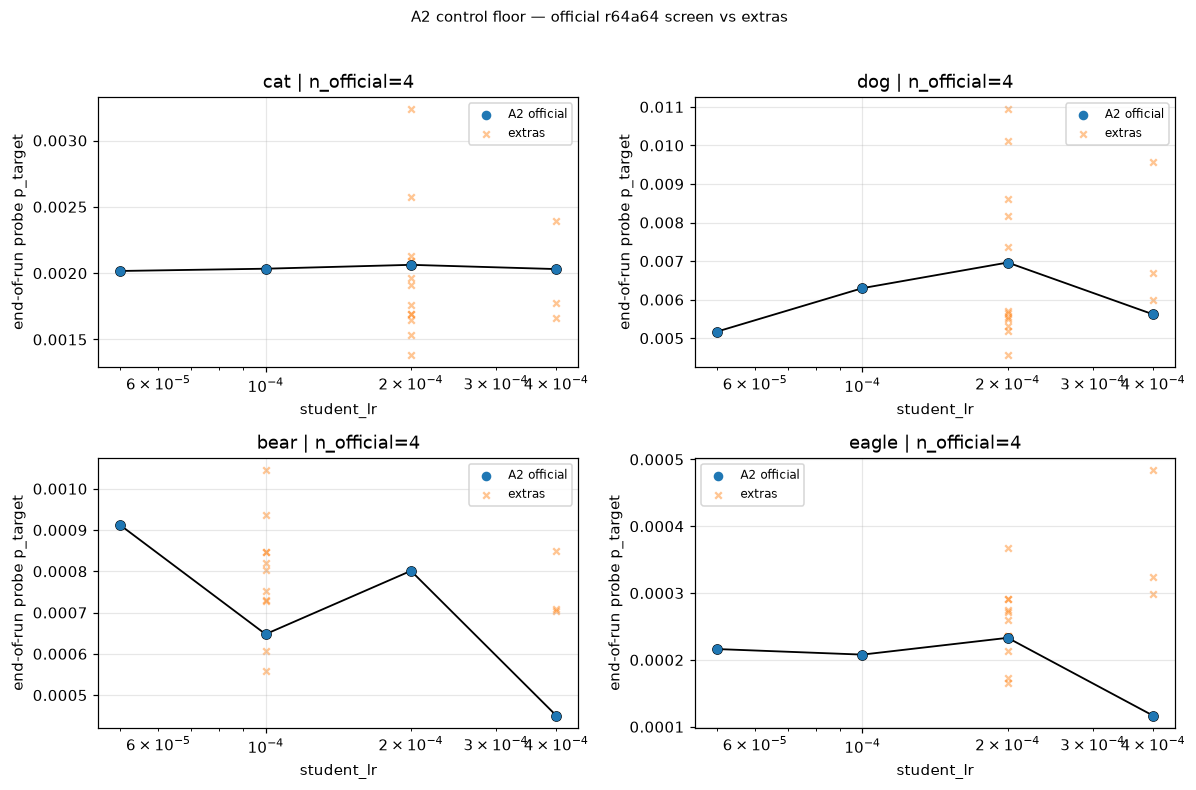

Cross-animal mean-floor ratio (max/min) = 31.1×
CONSEQUENCE: never pool raw p_target across animals. Use matched-control deltas or z-score within animal.


In [6]:
print("SCOPE A2 official + extras: Stage A control leaves")
a2 = eor_ctrl.copy()
official_dirs = set(leaves.loc[leaves["is_a2_official"], "run_dir"])
a2["official"] = a2["run_dir"].isin(official_dirs)
print(f"control eor leaves: {len(a2)}  official={int(a2.official.sum())}  "
      f"extras={int((~a2.official).sum())}")
if int(a2.official.sum()) != 16:
    print(
        f"NOTE: official A2 healthy eor is {int(a2.official.sum())}/16 — "
        "filesystem A2 completeness is asserted in §1."
    )

floor = (
    a2[a2["official"]]
    .groupby(["animal", "student_lr"], observed=True)["p_target"]
    .agg(["mean", "min", "max", "count"])
    .reset_index()
)
print("Official A2 end-of-run probe p_target:")
display(floor)

cf = pd.DataFrame(a1_sel.get("control_floor") or [])
print("A1 selection-report control_floor (eval-grade / gate input):")
display(cf[["animal", "student_lr", "floor_p_target"]])
print(
    f"Gate CONTROL_FLOOR_MAX={CONTROL_FLOOR_MAX}  "
    f"CONTROL_FLOOR_MAX_SPREAD={CONTROL_FLOOR_MAX_SPREAD}"
)
for animal in ANIMALS:
    sub = cf[cf["animal"] == animal]["floor_p_target"].astype(float)
    print(
        f"  {animal}: min={sub.min():.6f} max={sub.max():.6f} "
        f"spread={sub.max() - sub.min():.6f}  "
        f"pass_max={bool(sub.max() <= CONTROL_FLOOR_MAX)}  "
        f"pass_spread={bool((sub.max() - sub.min()) <= CONTROL_FLOOR_MAX_SPREAD)}"
    )
    assert float(sub.max()) <= CONTROL_FLOOR_MAX
    assert float(sub.max() - sub.min()) <= CONTROL_FLOOR_MAX_SPREAD

fig, axes = animal_grid(figsize=(11, 7), sharey=False)
for ax, animal in zip(axes, ANIMALS):
    sub = a2[(a2["animal"] == animal) & a2["official"]]
    extra = a2[(a2["animal"] == animal) & ~a2["official"]]
    ax.scatter(sub["student_lr"], sub["p_target"], s=28, label="A2 official", zorder=3)
    if len(extra):
        ax.scatter(
            extra["student_lr"], extra["p_target"], s=18, alpha=0.45,
            marker="x", label="extras",
        )
    means = sub.groupby("student_lr")["p_target"].mean().sort_index()
    ax.plot(means.index, means.values, "k-o", lw=1.2)
    ax.set_xscale("log")
    ax.set_title(f"{animal} | n_official={len(sub)}")
    ax.set_xlabel("student_lr")
    ax.set_ylabel("end-of-run probe p_target")
    ax.legend(fontsize=8)
fig.suptitle("A2 control floor — official r64a64 screen vs extras", y=1.02, fontsize=10)
plt.tight_layout()
plt.show()

per_an = cf.groupby("animal")["floor_p_target"].mean()
ratio = float(per_an.max() / per_an.min()) if float(per_an.min()) > 0 else np.nan
print(f"Cross-animal mean-floor ratio (max/min) = {ratio:.1f}×")
print(
    "CONSEQUENCE: never pool raw p_target across animals. "
    "Use matched-control deltas or z-score within animal."
)
CONTROL_FLOOR = cf.groupby("animal")["floor_p_target"].mean().to_dict()


## 3. The HP surface per animal

**What this measures.** Same-init, healthy, end-of-run A1 probes on the
9 × 4 LoRA grid at e=1, gseed0. One panel per animal. The frozen recipe is
boxed via `highlight=`. Probe-grade — not the eval-grade freeze score.


SCOPE: 144 configs | 4 animal(s) x 1 base model(s) | seeds pre-averaged | A1 same-init healthy eor, gseed0
SCOPE A1 same-init money cells: 144 (expect 144 if all healthy)
colour scale vmax = 95th pct = 0.343


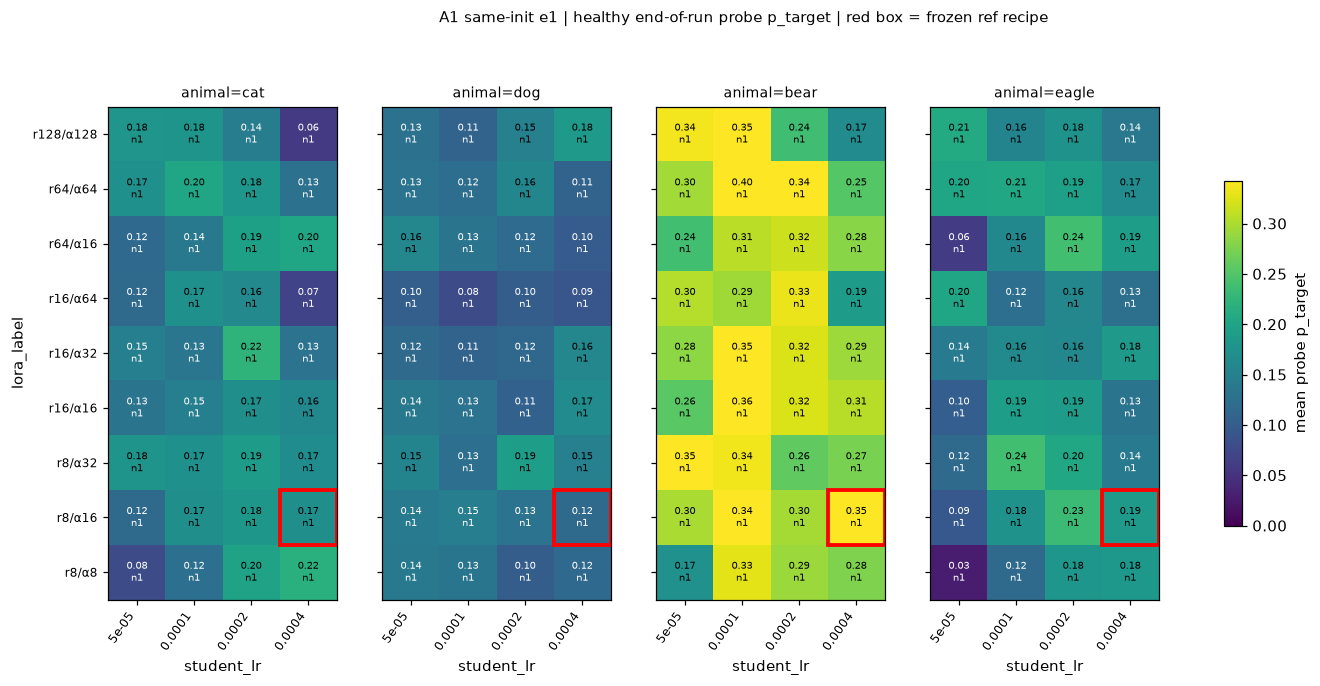

Per-animal A1 best (final probe) vs frozen ref:
  cat: best lora-r16a32@2e-04 p=0.2226  ref p=0.1710
  dog: best lora-r8a32@2e-04 p=0.1911  ref p=0.1184
  bear: best lora-r64a64@1e-04 p=0.3957  ref p=0.3466
  eagle: best lora-r64a16@2e-04 p=0.2396  ref p=0.1850


In [7]:
money = eor_treat[
    ~eor_treat["teacher_cross_init"].fillna(False).astype(bool)
    & eor_treat["num_epochs"].map(lambda e: math.isclose(float(e), 1.0))
    & (eor_treat["gseed"] == 0)
    & eor_treat.apply(
        lambda r: in_a1_recipe(r.student_lora_r, r.student_lora_alpha, r.student_lr),
        axis=1,
    )
].copy()
money = with_lora_label(money)
print_scope(money, note="A1 same-init healthy eor, gseed0")
expect_money = len(ANIMALS) * len(A1_STUDENT_MODES) * len(A1_LORA_LRS)
print(f"SCOPE A1 same-init money cells: {len(money)} (expect {expect_money} if all healthy)")
if len(money) != expect_money:
    print(
        f"NOTE: {expect_money - len(money)} A1 same-init cells missing from healthy "
        "eor (diverged or not loaded). Filesystem A1 completeness is asserted in §1."
    )

fr = freeze["winner"]["recipe"]
frozen_label = f"r{fr['lora_r']}/α{fr['lora_alpha']}"
vmax = float(np.nanpercentile(money["p_target"], 95))
print(f"colour scale vmax = 95th pct = {vmax:.3f}")

fig = aplots.facet_grid_heatmaps(
    money,
    row="lora_label",
    col="student_lr",
    val="p_target",
    col_facet="animal",
    agg="mean",
    show_n=True,
    cmap="viridis",
    vmin=0.0,
    vmax=vmax,
    orders={
        "student_lr": list(A1_LORA_LRS),
        "animal": list(ANIMALS),
    },
    highlight=[{
        "lora_label": frozen_label,
        "student_lr": fr["lr"],
        "color": "red",
        "lw": 2.5,
    }],
    title=(
        "A1 same-init e1 | healthy end-of-run probe p_target | "
        "red box = frozen ref recipe"
    ),
    cbar_label="mean probe p_target",
    panel_w=3.6,
    row_h=0.38,
    fmt="{:.2f}",
)
plt.show()

print("Per-animal A1 best (final probe) vs frozen ref:")
for animal in ANIMALS:
    sub = money[money["animal"] == animal]
    best = sub.sort_values("p_target", ascending=False).iloc[0]
    ref = sub[
        (sub["student_lora_r"] == fr["lora_r"])
        & (sub["student_lora_alpha"] == fr["lora_alpha"])
        & np.isclose(sub["student_lr"], fr["lr"])
    ]
    ref_p = float(ref["p_target"].mean()) if len(ref) else np.nan
    print(
        f"  {animal}: best {mode_token(best.student_lora_r, best.student_lora_alpha)}"
        f"@{best.student_lr:.0e} p={best.p_target:.4f}  "
        f"ref p={ref_p:.4f}"
    )


## 4. Cross-animal consistency of the HP surface

**What this measures.** Whether the A1 recipe ranking is shared across animals
(Spearman of recipe-mean `p_target`), whether a z-scored pooled surface still
shows a ridge, and whether the frozen recipe sits on-ridge for all four
animals or only some. Rank correlations — not pooled raw `p_target`.


SCOPE: 144 configs | 4 animal(s) x 1 base model(s) | seeds pre-averaged | A1 same-init recipe surface for cross-animal ranks
recipe-mean matrix: (36, 4) (recipes × animals)
Spearman ρ of recipe-mean p_target:


,cat,dog,bear,eagle
cat,1.000,-0.231,0.381,0.579
dog,-0.231,1.000,-0.138,-0.163
bear,0.381,-0.138,1.000,0.350
eagle,0.579,-0.163,0.350,1.000


p-values:


,cat,dog,bear,eagle
cat,0.0000,0.1750,0.0218,0.0002
dog,0.1750,0.0000,0.4206,0.3432
bear,0.0218,0.4206,0.0000,0.0363
eagle,0.0002,0.3432,0.0363,0.0000


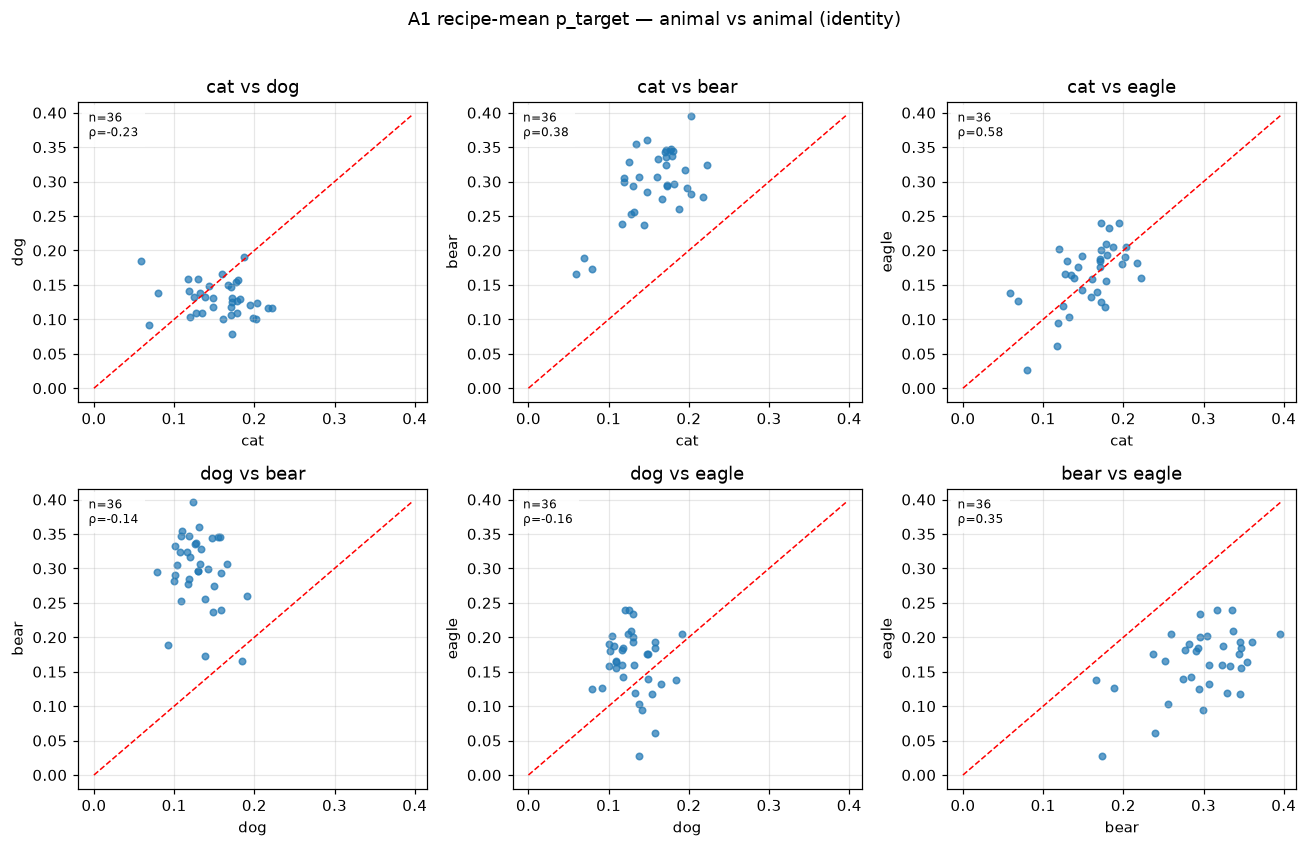

SCOPE: 144 configs | 4 animal(s) x 1 base model(s) | seeds pre-averaged | z-score within animal, then pool


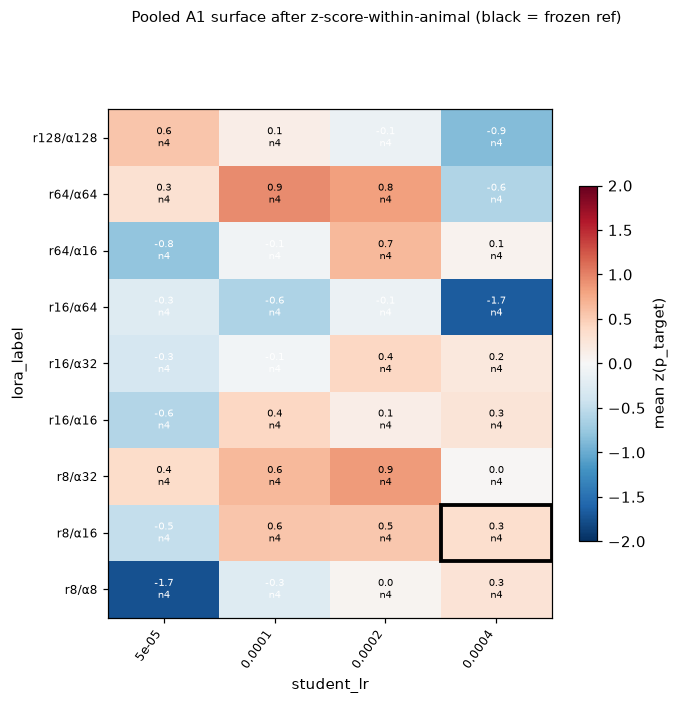

Does the frozen recipe sit on-ridge per animal?
  cat: frozen rank 16/36  p=0.1710  best=0.2226  on_ridge(top-5)=False
  dog: frozen rank 23/36  p=0.1184  best=0.1911  on_ridge(top-5)=False
  bear: frozen rank 5/36  p=0.3466  best=0.3957  on_ridge(top-5)=True
  eagle: frozen rank 13/36  p=0.1850  best=0.2396  on_ridge(top-5)=False
VERDICT: frozen ref is on-ridge (top-5 of 36) for 1/4 animals — a compromise, not a universal peak.


In [8]:
print_scope(money, note="A1 same-init recipe surface for cross-animal ranks")
recipe_means = (
    money.groupby(
        ["animal", "student_lora_r", "student_lora_alpha", "student_lr"],
        as_index=False,
    )["p_target"].mean()
)
recipe_means["recipe"] = recipe_means.apply(
    lambda r: recipe_label(r.student_lora_r, r.student_lora_alpha, r.student_lr),
    axis=1,
)
wide = recipe_means.pivot(index="recipe", columns="animal", values="p_target")
print(f"recipe-mean matrix: {wide.shape} (recipes × animals)")
rho = pd.DataFrame(index=list(ANIMALS), columns=list(ANIMALS), dtype=float)
pval = rho.copy()
for a, b in combinations(ANIMALS, 2):
    pair = wide[[a, b]].dropna()
    stat = spearmanr(pair[a], pair[b])
    rho.loc[a, b] = rho.loc[b, a] = float(stat.statistic)
    pval.loc[a, b] = pval.loc[b, a] = float(stat.pvalue)
for a in ANIMALS:
    rho.loc[a, a] = 1.0
    pval.loc[a, a] = 0.0
print("Spearman ρ of recipe-mean p_target:")
display(rho.round(3))
print("p-values:")
display(pval.round(4))

fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
pairs = list(combinations(ANIMALS, 2))
for ax, (a, b) in zip(axes.ravel(), pairs):
    pair = wide[[a, b]].dropna().reset_index()
    pair = pair.rename(columns={a: "x", b: "y"})
    aplots.identity_scatter(
        ax, pair, "x", "y", stat="spearman",
        diag_lim=(0.0, float(np.nanmax(wide.values))),
        textbox=True, title_stats=False, s=18, alpha=0.7,
    )
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}")
fig.suptitle("A1 recipe-mean p_target — animal vs animal (identity)", y=1.02)
plt.tight_layout()
plt.show()

zmoney = money.copy()
zmoney["p_z"] = zmoney.groupby("animal")["p_target"].transform(
    lambda s: (s - s.mean()) / s.std(ddof=1)
)
print_scope(zmoney, note="z-score within animal, then pool")
fig = aplots.facet_grid_heatmaps(
    zmoney,
    row="lora_label",
    col="student_lr",
    val="p_z",
    agg="mean",
    show_n=True,
    cmap="RdBu_r",
    vmin=-2.0,
    vmax=2.0,
    mid=0.0,
    orders={"student_lr": list(A1_LORA_LRS)},
    highlight=[{
        "lora_label": frozen_label,
        "student_lr": fr["lr"],
        "color": "black",
        "lw": 2.5,
    }],
    title="Pooled A1 surface after z-score-within-animal (black = frozen ref)",
    cbar_label="mean z(p_target)",
    panel_w=5.5,
    row_h=0.40,
    fmt="{:.1f}",
)
plt.show()

print("Does the frozen recipe sit on-ridge per animal?")
ridge_rows = []
for animal in ANIMALS:
    sub = recipe_means[recipe_means["animal"] == animal].sort_values(
        "p_target", ascending=False
    ).reset_index(drop=True)
    hit = sub[
        (sub["student_lora_r"] == fr["lora_r"])
        & (sub["student_lora_alpha"] == fr["lora_alpha"])
        & np.isclose(sub["student_lr"], fr["lr"])
    ]
    rank = int(hit.index[0]) + 1 if len(hit) else -1
    n = len(sub)
    p_ref = float(hit["p_target"].iloc[0]) if len(hit) else np.nan
    p_best = float(sub["p_target"].iloc[0])
    ridge_rows.append({
        "animal": animal, "ref_rank": rank, "n_recipes": n,
        "ref_p": p_ref, "best_p": p_best,
        "on_ridge": rank <= 5 if rank > 0 else False,
    })
    print(
        f"  {animal}: frozen rank {rank}/{n}  p={p_ref:.4f}  "
        f"best={p_best:.4f}  on_ridge(top-5)={rank <= 5}"
    )
ridge_tbl = pd.DataFrame(ridge_rows)
print(
    "VERDICT: frozen ref is on-ridge (top-5 of 36) for "
    f"{int(ridge_tbl.on_ridge.sum())}/{len(ridge_tbl)} animals — "
    "a compromise, not a universal peak."
)


## 5. Is there an lr × α law?

**What this measures.** A quadratic in log-lr (turning point + bootstrap CI)
and Spearman on the monotone alternative `p_target` vs `log10(lr·α)`. Tested
per animal on the A1 same-init surface — not asserted.


SCOPE: 144 configs | 4 animal(s) x 1 base model(s) | seeds pre-averaged | A1 same-init for lr×α law


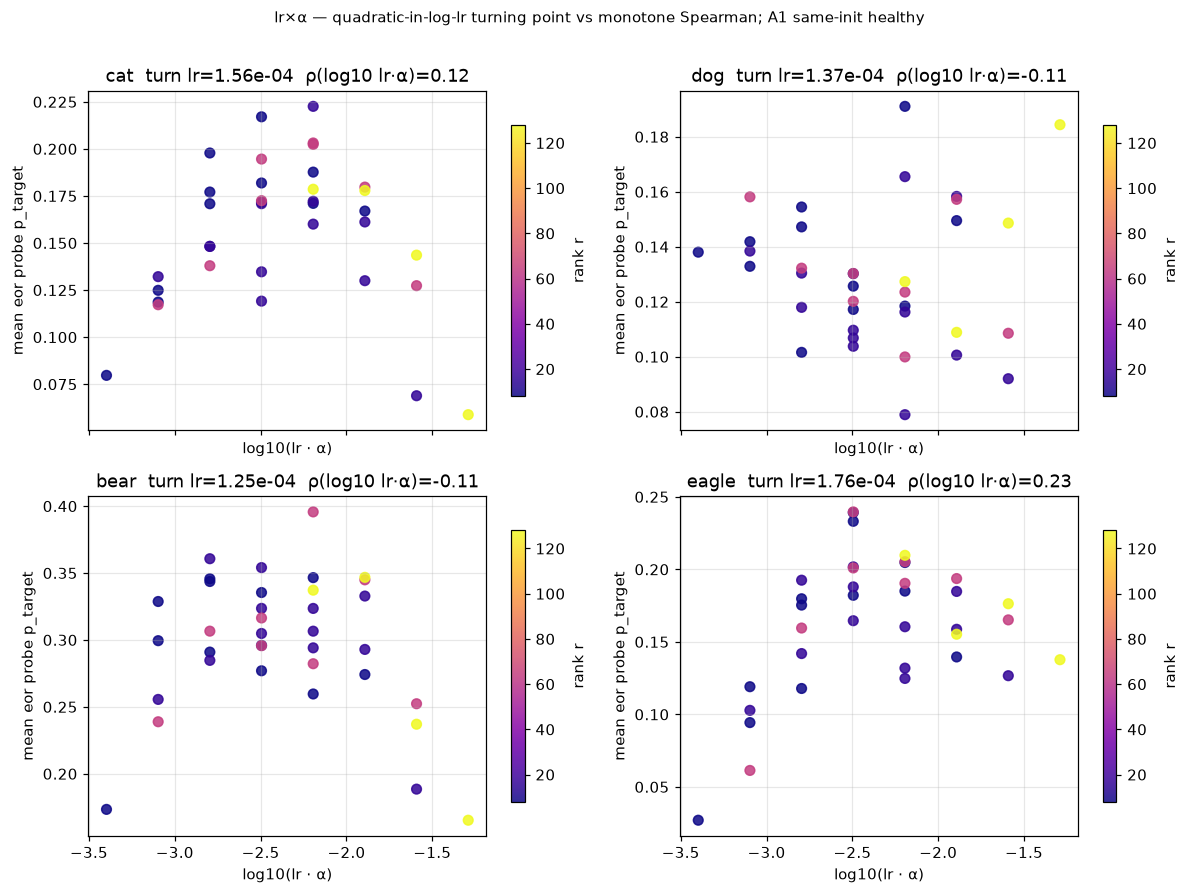

,animal,n,turn_log10_lr,turn_lr,turn_ci_low_lr,turn_ci_high_lr,spearman_log10_lr_alpha,spearman_p
0,cat,36,-3.8072,0.0002,0.0001,0.0004,0.1188,0.4901
1,dog,36,-3.8638,0.0001,0.0000,0.0024,-0.1104,0.5213
2,bear,36,-3.9042,0.0001,0.0001,0.0002,-0.1059,0.5388
3,eagle,36,-3.7545,0.0002,0.0001,0.0002,0.2314,0.1746


VERDICT: a monotone lr·α law is rejected when |Spearman| is small / p is large; the turning-point CI says whether an interior ridge is identifiable. Read the table, do not assume a rising law.


In [9]:
print_scope(money, note="A1 same-init for lr×α law")
ridge = money.copy()
ridge["lr_alpha"] = ridge["student_lr"] * ridge["student_lora_alpha"]
ridge["log10_lr"] = np.log10(ridge["student_lr"].astype(float))
ridge["log10_lr_alpha"] = np.log10(ridge["lr_alpha"].astype(float))


def _quad_turn(log_lr: np.ndarray, y: np.ndarray) -> float:
    if len(log_lr) < 3:
        return float("nan")
    c2, c1, _c0 = np.polyfit(log_lr, y, 2)
    if abs(c2) < 1e-18:
        return float("nan")
    return float(-c1 / (2.0 * c2))


fig, axes = animal_grid(figsize=(11, 8), sharex=True)
law_rows = []
rng = np.random.default_rng(BOOTSTRAP_SEED)
for ax, animal in zip(axes, ANIMALS):
    sub = ridge[ridge["animal"] == animal]
    g = (
        sub.groupby(
            ["student_lora_r", "student_lora_alpha", "student_lr",
             "log10_lr", "log10_lr_alpha"],
            as_index=False,
        )["p_target"].mean()
    )
    sc = ax.scatter(
        g["log10_lr_alpha"], g["p_target"],
        c=g["student_lora_r"], cmap="plasma", s=40, alpha=0.85,
    )
    x = g["log10_lr"].to_numpy()
    y = g["p_target"].to_numpy()
    turn = _quad_turn(x, y)
    boots = []
    for _ in range(2000):
        idx = rng.integers(0, len(x), size=len(x))
        boots.append(_quad_turn(x[idx], y[idx]))
    boots = np.asarray(boots, dtype=float)
    boots = boots[np.isfinite(boots)]
    lo, hi = (np.quantile(boots, [0.025, 0.975]) if len(boots) else (np.nan, np.nan))
    rho_mono = float(spearmanr(g["log10_lr_alpha"], g["p_target"]).statistic)
    p_mono = float(spearmanr(g["log10_lr_alpha"], g["p_target"]).pvalue)
    law_rows.append({
        "animal": animal, "n": len(g),
        "turn_log10_lr": turn,
        "turn_lr": 10 ** turn if np.isfinite(turn) else np.nan,
        "turn_ci_low_lr": 10 ** lo if np.isfinite(lo) else np.nan,
        "turn_ci_high_lr": 10 ** hi if np.isfinite(hi) else np.nan,
        "spearman_log10_lr_alpha": rho_mono,
        "spearman_p": p_mono,
    })
    ax.set_title(
        f"{animal}  turn lr={10 ** turn:.2e}  "
        f"ρ(log10 lr·α)={rho_mono:.2f}"
    )
    ax.set_xlabel("log10(lr · α)")
    ax.set_ylabel("mean eor probe p_target")
    fig.colorbar(sc, ax=ax, shrink=0.8, label="rank r")
fig.suptitle(
    "lr×α — quadratic-in-log-lr turning point vs monotone Spearman; "
    "A1 same-init healthy",
    y=1.01, fontsize=10,
)
plt.tight_layout()
plt.show()
law_tbl = pd.DataFrame(law_rows)
display(law_tbl.round(4))
print(
    "VERDICT: a monotone lr·α law is rejected when |Spearman| is small / "
    "p is large; the turning-point CI says whether an interior ridge is "
    "identifiable. Read the table, do not assume a rising law."
)


## 6. Divergence and instability map

**What this measures.** Leaf-level `diverged` (non-finite probe metrics or
PPL > `DIVERGENCE_PPL_FACTOR` × first-row PPL) plus two known bad capability
rows that must be excluded from PPL aggregates via a finite mask.


DIVERGENCE_PPL_FACTOR = 10.0
Diverged Stage A leaves: 36 / 693
Diverged-leaf table:


,animal,student_lr,num_epochs,student_lora_r,student_lora_alpha,gseed,p_target,ppl,gkd_tag,teacher_cross_init,is_control
143,bear,0.0004,1.0,128,128,0,1.017193e-02,1.426546e+02,lmb1.0_b1.0_lora_lr4e-4_e1_r128a128,True,False
294,cat,0.0004,1.0,128,128,0,2.616918e-40,inf,lmb1.0_b1.0_lora_lr4e-4_e1_r128a128,True,False
420,dog,0.0004,0.5,128,128,2,1.526657e-01,1.554328e+02,lmb1.0_b1.0_lora_lr4e-4_e0.5_r128a128,False,False
447,dog,0.0004,3.0,128,128,0,6.867942e-03,1.096304e+02,lmb1.0_b1.0_lora_lr4e-4_e3_r128a128,False,False
448,dog,0.0004,3.0,128,128,1,4.827803e-02,1.473513e+02,lmb1.0_b1.0_lora_lr4e-4_e3_r128a128,False,False
449,dog,0.0004,3.0,128,128,2,2.499553e-29,1.936729e+25,lmb1.0_b1.0_lora_lr4e-4_e3_r128a128,False,False
459,dog,0.0004,5.0,128,128,0,5.780269e-02,8.264143e+01,lmb1.0_b1.0_lora_lr4e-4_e5_r128a128,False,False
460,dog,0.0004,5.0,128,128,1,8.388670e-24,5.787132e+20,lmb1.0_b1.0_lora_lr4e-4_e5_r128a128,False,False
461,dog,0.0004,5.0,128,128,2,6.643508e-02,1.077122e+02,lmb1.0_b1.0_lora_lr4e-4_e5_r128a128,False,False
521,dog,0.0004,1.0,128,128,0,4.666674e-02,1.405583e+02,lmb1.0_b1.0_lora_lr4e-4_e1_r128a128,True,False


Capability rows dropped by finite-mask: 1 / 413
Named bad capability rows (exclude from PPL aggregates):


,animal,teacher_tag,gkd_tag,is_control,ppl_overall_mean,perplexity_ratio
479,eagle,sdf-ep5_lr5e-5_r128a128-tfs0,lmb1.0_b1.0_lora_lr8e-4_e3_r16a64,False,inf,inf


Relative config dirs:
  eagle/pythia-160m-data-seed1/sdf-ep5_lr5e-5_r128a128-tfs0/lmb1.0_b1.0_lora_lr8e-4_e3_r16a64  ppl=inf ratio=inf
A1 money-grid healthy probe PPL: median=58.6 max=129.6


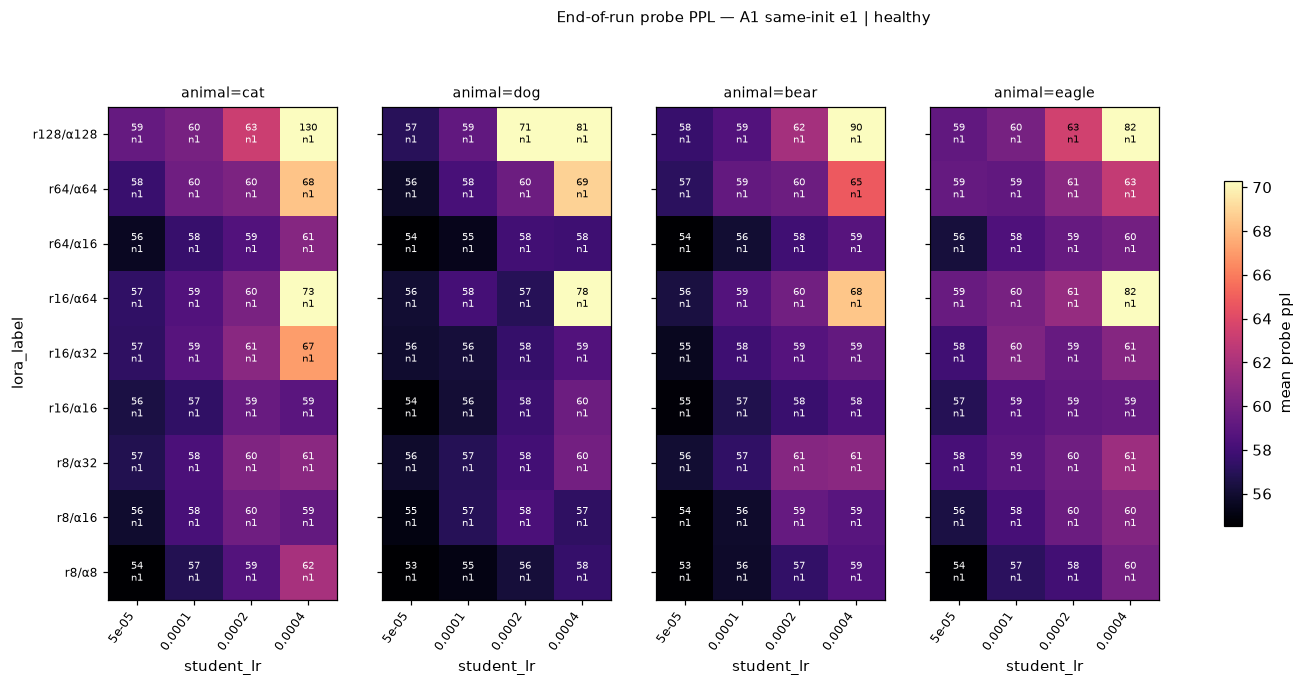

In [10]:
print(f"DIVERGENCE_PPL_FACTOR = {DIVERGENCE_PPL_FACTOR}")
hp_eor_raw = end_of_run_probes(probes)
print(f"Diverged Stage A leaves: {int(hp_eor_raw['diverged'].sum())} / {len(hp_eor_raw)}")
div_tbl = hp_eor_raw[hp_eor_raw["diverged"]][
    ["animal", "student_lr", "num_epochs", "student_lora_r",
     "student_lora_alpha", "gseed", "p_target", "ppl", "gkd_tag",
     "teacher_cross_init", "is_control"]
].sort_values(["animal", "student_lora_r", "student_lr"])
print("Diverged-leaf table:")
display(div_tbl if len(div_tbl) else pd.DataFrame({"note": ["none"]}))

cap_sa = cap.copy()
ppl = cap_sa["ppl_overall_mean"].to_numpy(dtype=float)
ratio = cap_sa["perplexity_ratio"].to_numpy(dtype=float)
finite = np.isfinite(ppl) & np.isfinite(ratio)
n_drop = int((~finite).sum())
print(f"Capability rows dropped by finite-mask: {n_drop} / {len(cap_sa)}")
bad = cap_sa.loc[~finite, [
    "animal", "teacher_tag", "gkd_tag", "is_control",
    "ppl_overall_mean", "perplexity_ratio",
]]
print("Named bad capability rows (exclude from PPL aggregates):")
display(bad)
print("Relative config dirs:")
for rec in bad.itertuples():
    arm = "controls" if rec.is_control else rec.teacher_tag
    print(f"  {rec.animal}/{STAGE_A_STUDENT}/{arm}/{rec.gkd_tag}  "
          f"ppl={rec.ppl_overall_mean} ratio={rec.perplexity_ratio}")

ppl_grid = with_lora_label(money.copy())
print(
    f"A1 money-grid healthy probe PPL: "
    f"median={float(ppl_grid['ppl'].median()):.1f} "
    f"max={float(ppl_grid['ppl'].max()):.1f}"
)
fig = aplots.facet_grid_heatmaps(
    ppl_grid,
    row="lora_label", col="student_lr", val="ppl",
    col_facet="animal",
    agg="mean", show_n=True, cmap="magma",
    vmin=float(ppl_grid["ppl"].quantile(0.05)),
    vmax=float(ppl_grid["ppl"].quantile(0.95)),
    orders={"student_lr": list(A1_LORA_LRS), "animal": list(ANIMALS)},
    title="End-of-run probe PPL — A1 same-init e1 | healthy",
    cbar_label="mean probe ppl", panel_w=3.6, row_h=0.38, fmt="{:.0f}",
)
plt.show()


## 7. Dose ladder

**What this measures.** A3 same-init arms over `A3_DOSES`, peak-then-decay
(`final/peak < 0.8`), Spearman(dose, `p_target`), and pairwise dose contrasts.
`dose_response` bands are `z * std / sqrt(n)`, not t-intervals.


SCOPE: 268 configs | 4 animal(s) x 1 base model(s) | seeds pre-averaged | A3 same-init ladder (healthy eor)
doses present: [np.float64(0.5), np.float64(1.0), np.float64(3.0), np.float64(5.0)]
A3_DOSES plan: (0.5, 1.0, 3.0, 5.0)


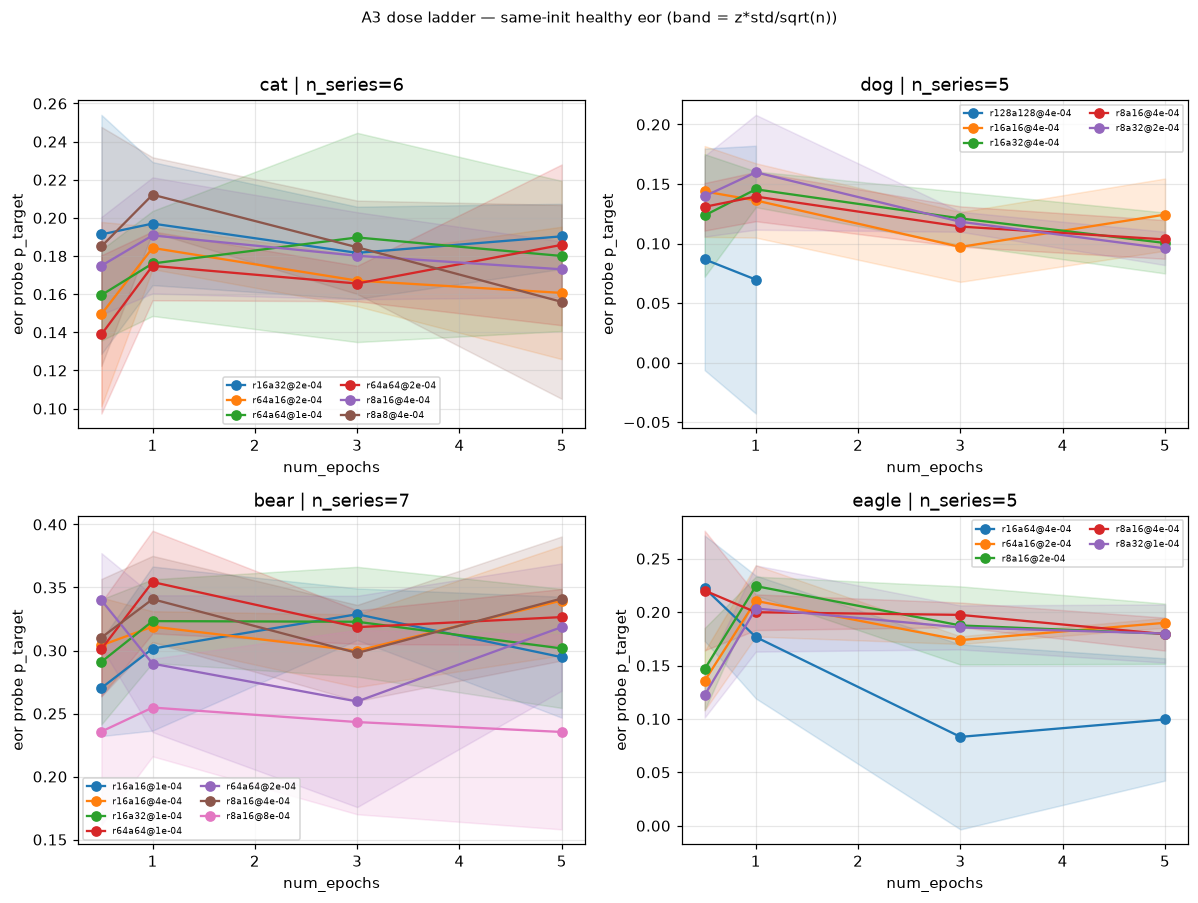

Mean eor p_target by animal × dose:


num_epochs,0.5,1.0,3.0,5.0
animal,,,,
bear,0.293,0.312,0.296,0.308
cat,0.167,0.189,0.178,0.174
dog,0.128,0.130,0.113,0.106
eagle,0.169,0.203,0.165,0.170


In [11]:
a3_mask = eor_treat["run_dir"].isin(set(leaves.loc[leaves["is_a3"], "run_dir"]))
dose = eor_treat[
    ~eor_treat["teacher_cross_init"].fillna(False).astype(bool)
    & eor_treat["num_epochs"].map(lambda e: _isclose_any(e, A3_DOSES))
].copy()
ladder_keys = (
    dose.groupby(["animal", "student_lora_r", "student_lora_alpha", "student_lr"])
    ["num_epochs"].nunique()
)
keep = ladder_keys[ladder_keys >= 2].reset_index()
dose = dose.merge(
    keep.drop(columns="num_epochs"),
    on=["animal", "student_lora_r", "student_lora_alpha", "student_lr"],
    how="inner",
)
dose["recipe"] = dose.apply(
    lambda r: recipe_label(r.student_lora_r, r.student_lora_alpha, r.student_lr),
    axis=1,
)
print_scope(dose, note="A3 same-init ladder (healthy eor)")
print("doses present:", sorted(dose["num_epochs"].dropna().unique()))
print("A3_DOSES plan:", A3_DOSES)

fig, axes = animal_grid(figsize=(11, 8), sharey=False)
for ax, animal in zip(axes, ANIMALS):
    sub = dose[dose["animal"] == animal]
    drawn = aplots.dose_response(
        ax, sub, x="num_epochs", y="p_target", group="recipe",
        order=None, ci=True,
    )
    ax.set_title(f"{animal} | n_series={drawn}")
    ax.set_xlabel("num_epochs")
    ax.set_ylabel("eor probe p_target")
    ax.legend(fontsize=6, ncol=2)
fig.suptitle(
    "A3 dose ladder — same-init healthy eor (band = z*std/sqrt(n))",
    y=1.02, fontsize=10,
)
plt.tight_layout()
plt.show()

print("Mean eor p_target by animal × dose:")
display(
    dose.groupby(["animal", "num_epochs"])["p_target"]
    .mean().unstack("num_epochs").round(3)
)


Stage A treat leaves with final/peak < 0.8: 268 / 582 = 46.0%


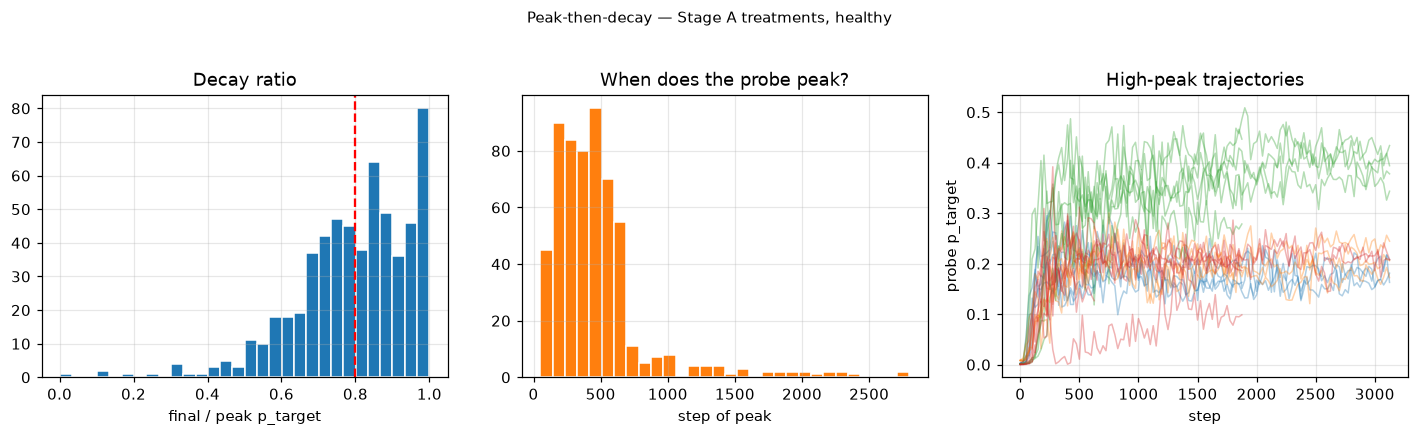

Spearman(dose, p_target) per animal (A3 same-init ladder leaves):


,animal,n,spearman,p
0,cat,72,0.0526,0.6608
1,dog,53,-0.3692,0.0065
2,bear,84,0.0834,0.4505
3,eagle,59,-0.0529,0.6905


Pairwise dose contrasts (mean p_target later − earlier), same-init A3:


,animal,d0,d1,delta,n0,n1
0,cat,0.5,1.0,0.0227,18,18
1,cat,0.5,3.0,0.0116,18,18
2,cat,0.5,5.0,0.0078,18,18
3,cat,1.0,3.0,-0.0111,18,18
4,cat,1.0,5.0,-0.0149,18,18
5,cat,3.0,5.0,-0.0038,18,18
6,dog,0.5,1.0,0.0025,14,15
7,dog,0.5,3.0,-0.0150,14,12
8,dog,0.5,5.0,-0.0216,14,12
9,dog,1.0,3.0,-0.0174,15,12


In [12]:
pt = peak_treat[["run_dir", "p_target", "step"]].rename(
    columns={"p_target": "peak_p_target", "step": "peak_step"}
)
merged = eor_treat.merge(pt, on="run_dir", how="inner")
merged["final_over_peak"] = merged["p_target"] / merged["peak_p_target"].replace(0, np.nan)
merged["below_80pct_peak"] = merged["final_over_peak"] < 0.8
print(
    f"Stage A treat leaves with final/peak < 0.8: "
    f"{int(merged['below_80pct_peak'].sum())} / {len(merged)} "
    f"= {float(merged['below_80pct_peak'].mean()):.1%}"
)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].hist(merged["final_over_peak"].dropna(), bins=30, color="C0", edgecolor="white")
axes[0].axvline(0.8, color="red", ls="--")
axes[0].set_xlabel("final / peak p_target")
axes[0].set_title("Decay ratio")
axes[1].hist(merged["peak_step"].dropna(), bins=30, color="C1", edgecolor="white")
axes[1].set_xlabel("step of peak")
axes[1].set_title("When does the probe peak?")
ax = axes[2]
for animal in ANIMALS:
    sub = merged[merged["animal"] == animal].nlargest(6, "peak_p_target")
    for rd in sub["run_dir"]:
        t = probes_h[probes_h["run_dir"] == rd].sort_values("step")
        ax.plot(t["step"], t["p_target"], color=ANIMAL_COLORS[animal], alpha=0.35, lw=1)
ax.set_xlabel("step")
ax.set_ylabel("probe p_target")
ax.set_title("High-peak trajectories")
fig.suptitle("Peak-then-decay — Stage A treatments, healthy", y=1.03, fontsize=10)
plt.tight_layout()
plt.show()

print("Spearman(dose, p_target) per animal (A3 same-init ladder leaves):")
sp_rows = []
for animal in ANIMALS:
    sub = dose[dose["animal"] == animal]
    if len(sub) < 4:
        continue
    st = spearmanr(sub["num_epochs"], sub["p_target"])
    sp_rows.append({
        "animal": animal, "n": len(sub),
        "spearman": float(st.statistic), "p": float(st.pvalue),
    })
display(pd.DataFrame(sp_rows).round(4))

print("Pairwise dose contrasts (mean p_target later − earlier), same-init A3:")
contrasts = []
doses = sorted(dose["num_epochs"].unique())
for animal in ANIMALS:
    sub = dose[dose["animal"] == animal]
    means = sub.groupby("num_epochs")["p_target"].mean()
    for i, d0 in enumerate(doses):
        for d1 in doses[i + 1:]:
            if d0 not in means or d1 not in means:
                continue
            contrasts.append({
                "animal": animal, "d0": d0, "d1": d1,
                "delta": float(means[d1] - means[d0]),
                "n0": int((sub["num_epochs"] == d0).sum()),
                "n1": int((sub["num_epochs"] == d1).sum()),
            })
display(pd.DataFrame(contrasts).round(4))


## 8. The A3 `ref` arm as a cross-animal HP-transfer test

**What this measures.** The freeze winner is the injected carry-over recipe
(`A3_REFERENCE_RECIPE`), not any animal's own A1 winner. Per animal, compare
Δ(ref) to Δ(that animal's own A1-best) at matched dose e=1 and quantify the
regret of using one shared recipe. This is a headline section.


A1 selection vs injected ref (from a1_selection_report):
  cat: selected n=5
  dog: selected n=5
  bear: selected n=7
  eagle: selected n=5


,animal,n_selected,own_best_r,own_best_a,own_best_lr,own_final,own_peak,own_by_final,own_by_peak,ref_final,ref_peak,ref_selected_final,ref_selected_peak,ref_final_rank
0,cat,5,16,32,0.0002,0.2226,0.2742,True,True,0.1710,0.2199,False,False,15
1,dog,5,8,32,0.0002,0.1911,0.2372,True,True,0.1184,0.1706,False,False,22
2,bear,7,64,64,0.0001,0.3957,0.4177,True,False,0.3466,0.4448,False,True,4
3,eagle,5,64,16,0.0002,0.2396,0.2863,True,True,0.1850,0.1850,False,False,12


HEADLINE: the freeze winner is the injected ref arm (r8a16@0.0004), not any animal's own A1 winner.
SCOPE: 4 configs | 4 animal(s) x 0 base model(s) | seeds pre-averaged | e=1 same-init test/prob loose-join deltas


,animal,delta_ref,n_treat_ref,delta_own_a1best,n_treat_own,regret_own_minus_ref
0,cat,0.2537,1,0.2752,1,0.0216
1,dog,0.1724,1,0.1926,1,0.0202
2,bear,0.4154,1,0.4557,1,0.0404
3,eagle,0.2414,1,0.2829,1,0.0415


Regret > 0 means the animal's own A1-best beats the shared ref at e=1. A shared freeze can still be the right cross-animal compromise.


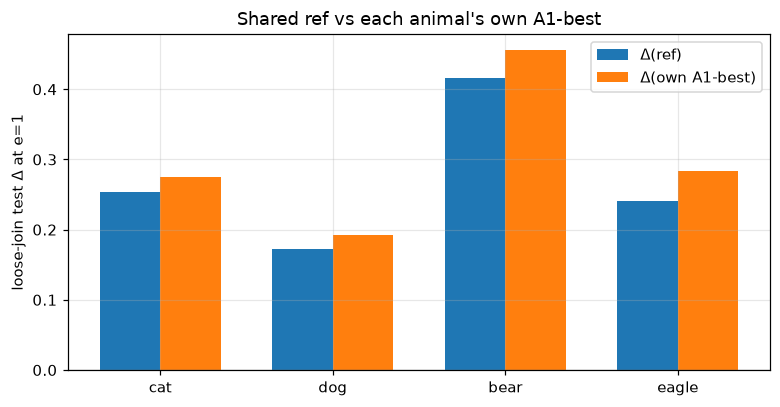

In [13]:
print("A1 selection vs injected ref (from a1_selection_report):")
sel_rows = []
for animal in ANIMALS:
    key = f"{animal}|1"
    block = (a1_sel.get("selection") or {}).get(key) or {}
    ranking = pd.DataFrame(block.get("ranking") or [])
    recipes = block.get("recipes") or []
    print(f"  {animal}: selected n={len(recipes)}")
    if ranking.empty:
        continue
    own = ranking.sort_values("final_rank").iloc[0]
    ref_hit = ranking[
        (ranking["lora_r"] == A3_REFERENCE_RECIPE.lora_r)
        & (ranking["lora_alpha"] == A3_REFERENCE_RECIPE.lora_alpha)
        & np.isclose(ranking["lr"], A3_REFERENCE_RECIPE.lr)
    ]
    sel_rows.append({
        "animal": animal,
        "n_selected": len(recipes),
        "own_best_r": int(own.lora_r),
        "own_best_a": int(own.lora_alpha),
        "own_best_lr": float(own.lr),
        "own_final": float(own.final_p_target),
        "own_peak": float(own.peak_p_target),
        "own_by_final": bool(own.selected_by_final),
        "own_by_peak": bool(own.selected_by_peak),
        "ref_final": float(ref_hit.iloc[0].final_p_target) if len(ref_hit) else np.nan,
        "ref_peak": float(ref_hit.iloc[0].peak_p_target) if len(ref_hit) else np.nan,
        "ref_selected_final": bool(ref_hit.iloc[0].selected_by_final) if len(ref_hit) else False,
        "ref_selected_peak": bool(ref_hit.iloc[0].selected_by_peak) if len(ref_hit) else False,
        "ref_final_rank": int(ref_hit.iloc[0].final_rank) if len(ref_hit) else -1,
    })
sel_tbl = pd.DataFrame(sel_rows)
display(sel_tbl.round(4))
print(
    "HEADLINE: the freeze winner is the injected ref arm "
    f"(r{A3_REFERENCE_RECIPE.lora_r}a{A3_REFERENCE_RECIPE.lora_alpha}"
    f"@{A3_REFERENCE_RECIPE.lr:g}), not any animal's own A1 winner."
)

pref_test = pref[(pref["set"] == "test") & (pref["scoring"] == "prob")].copy()
treat_si = pref_test[
    (~pref_test["is_control"])
    & (~pref_test["teacher_cross_init"].fillna(False).astype(bool))
]
ctrl_all = pref_test[pref_test["is_control"]]


def _loose_delta(animal: str, r, a, lr, dose: float = 1.0) -> tuple[float, int, int]:
    t = treat_si[
        (treat_si["animal"] == animal)
        & (treat_si["student_mode"] == "lora")
        & np.isclose(treat_si["beta"], 1.0)
        & (treat_si["student_lora_r"] == r)
        & (treat_si["student_lora_alpha"] == a)
        & np.isclose(treat_si["student_lr"], lr)
        & np.isclose(treat_si["num_epochs"], dose)
    ]
    c = ctrl_all[
        (ctrl_all["animal"] == animal)
        & (ctrl_all["model"] == STAGE_A_STUDENT)
        & np.isclose(ctrl_all["beta"], 1.0)
        & np.isclose(ctrl_all["num_epochs"], dose)
    ]
    if t.empty or c.empty:
        return float("nan"), len(t), len(c)
    return float(t["p_target"].mean()) - float(c["p_target"].mean()), len(t), len(c)


reg_rows = []
for rec in sel_tbl.itertuples():
    d_ref, nt_r, nc_r = _loose_delta(
        rec.animal, A3_REFERENCE_RECIPE.lora_r, A3_REFERENCE_RECIPE.lora_alpha,
        A3_REFERENCE_RECIPE.lr,
    )
    d_own, nt_o, nc_o = _loose_delta(
        rec.animal, rec.own_best_r, rec.own_best_a, rec.own_best_lr,
    )
    reg_rows.append({
        "animal": rec.animal,
        "delta_ref": d_ref, "n_treat_ref": nt_r,
        "delta_own_a1best": d_own, "n_treat_own": nt_o,
        "regret_own_minus_ref": d_own - d_ref,
    })
reg_tbl = pd.DataFrame(reg_rows)
print_scope(reg_tbl, note="e=1 same-init test/prob loose-join deltas")
display(reg_tbl.round(4))
print(
    "Regret > 0 means the animal's own A1-best beats the shared ref at e=1. "
    "A shared freeze can still be the right cross-animal compromise."
)

fig, ax = plt.subplots(figsize=(7.2, 3.8))
x = np.arange(len(ANIMALS))
w = 0.35
ax.bar(x - w / 2, reg_tbl.set_index("animal").loc[list(ANIMALS), "delta_ref"],
       width=w, label="Δ(ref)")
ax.bar(x + w / 2, reg_tbl.set_index("animal").loc[list(ANIMALS), "delta_own_a1best"],
       width=w, label="Δ(own A1-best)")
ax.set_xticks(x)
ax.set_xticklabels(list(ANIMALS))
ax.axhline(0, color="0.6", lw=0.8)
ax.set_ylabel("loose-join test Δ at e=1")
ax.set_title("Shared ref vs each animal's own A1-best")
ax.legend()
plt.tight_layout()
plt.show()


## 9. Emergence timing

**What this measures.** Step 0 is present, so timing is not left-censored.
Two rules: (1) **exploratory / not pre-registered** — first step exceeding
the per-animal control mean+2SD, sustained for three consecutive probes;
(2) t50 — first step at ≥50% of that leaf's peak. Reported per animal and
by LoRA rank.


SCOPE: 29545 configs | 4 animal(s) x 1 base model(s) | seeds pre-averaged | healthy Stage A trajectories


Probe steps include 0: True
Control mean+2SD (mean over steps): cat=0.0023, dog=0.0085, bear=0.0010, eagle=0.0004


Exploratory sustained-3 rule: 582 / 582 separated; 0 already above threshold at step 0 (not a pre-registered criterion).


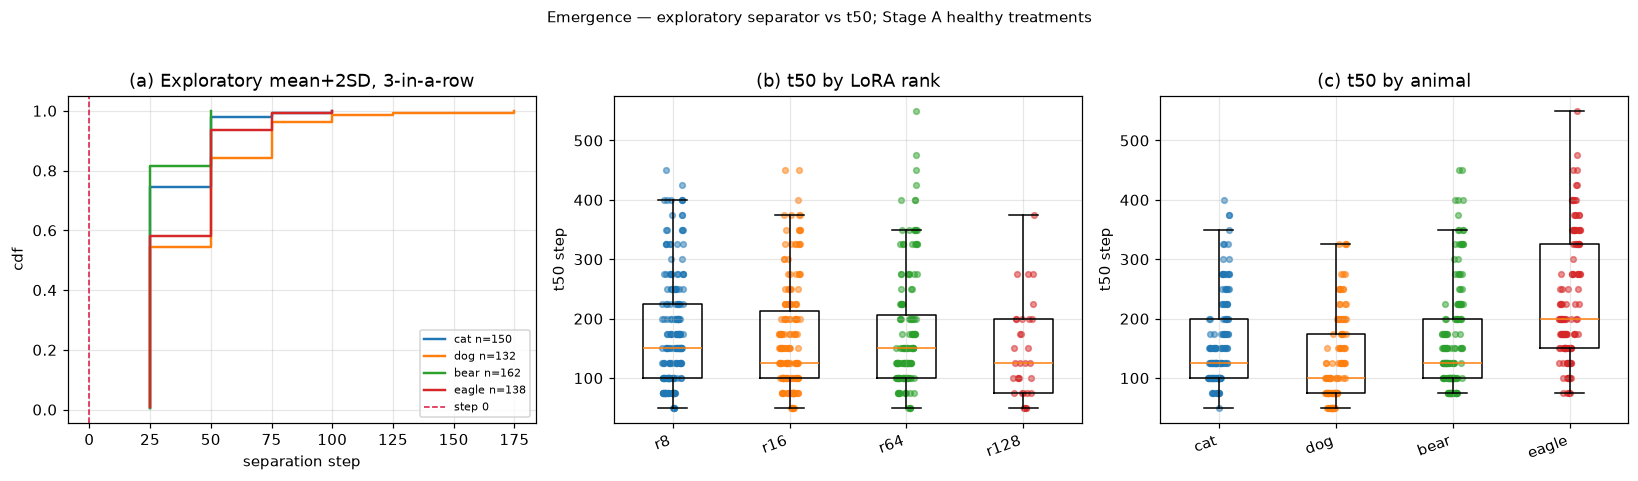

t50 by animal × dose:


median   mean  count
animal num_epochs                      
bear   0.5          100.0  115.6     24
       1.0          150.0  190.6     90
       3.0          125.0  132.3     24
       5.0          125.0  142.7     24
cat    0.5          100.0  107.1     21
       1.0          150.0  177.9     87
       3.0          125.0  133.3     21
       5.0          125.0  145.2     21
dog    0.5           75.0   82.4     17
       1.0          125.0  139.4     85
       3.0           75.0  100.0     15
       5.0           75.0  115.0     15
eagle  0.5          175.0  154.2     18
       1.0          250.0  250.6     85
       3.0          150.0  198.6     18
       5.0          175.0  219.1     17

t50 by LoRA rank:


,median,mean,count
student_lora_r,,,
8,150.0,170.3,215
16,125.0,164.2,183
64,150.0,175.2,152
128,125.0,145.3,32


In [14]:
print_scope(probes_h, note="healthy Stage A trajectories")
ctrl_traj = probes_h[probes_h["is_control"]]
ctrl_step = (
    ctrl_traj.groupby(["animal", "step"])["p_target"]
    .agg(["mean", "std"])
    .reset_index()
)
ctrl_step["sep_threshold"] = ctrl_step["mean"] + 2.0 * ctrl_step["std"].fillna(0.0)
treat_traj = probes_h[~probes_h["is_control"]].merge(
    ctrl_step[["animal", "step", "sep_threshold"]], on=["animal", "step"], how="left"
)
print(f"Probe steps include 0: {0 in set(treat_traj['step'])}")
print(
    "Control mean+2SD (mean over steps): "
    + ", ".join(
        f"{a}={ctrl_step.loc[ctrl_step.animal == a, 'sep_threshold'].mean():.4f}"
        for a in ANIMALS
        if a in set(ctrl_step["animal"])
    )
)

records = []
for rd, g in treat_traj.groupby("run_dir"):
    g = g.sort_values("step").reset_index(drop=True)
    peak_p = float(g["p_target"].max())
    above = (g["p_target"] > g["sep_threshold"]).to_numpy()
    sep_step = np.nan
    for i in range(0, max(len(above) - 2, 0)):
        if above[i] and above[i + 1] and above[i + 2]:
            sep_step = int(g.loc[i, "step"])
            break
    t50_hit = g[g["p_target"] >= 0.5 * peak_p]
    records.append({
        "run_dir": rd,
        "animal": g["animal"].iloc[0],
        "student_lora_r": g["student_lora_r"].iloc[0],
        "student_lr": float(g["student_lr"].iloc[0]),
        "num_epochs": float(g["num_epochs"].iloc[0]),
        "separated": np.isfinite(sep_step),
        "separation_step": sep_step,
        "t50_step": int(t50_hit["step"].iloc[0]) if len(t50_hit) else np.nan,
        "peak_p_target": peak_p,
        "at_step0": bool(above[0]) if len(above) else False,
    })
emerge = pd.DataFrame(records)
n_sep = int(emerge["separated"].sum())
n_s0 = int(emerge["at_step0"].sum())
print(
    f"Exploratory sustained-3 rule: {n_sep} / {len(emerge)} separated; "
    f"{n_s0} already above threshold at step 0 (not a pre-registered criterion)."
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
for animal in ANIMALS:
    v = np.sort(emerge.loc[emerge["animal"] == animal, "separation_step"].dropna())
    if len(v):
        ax.step(v, np.arange(1, len(v) + 1) / len(v), where="post",
                label=f"{animal} n={len(v)}", color=ANIMAL_COLORS[animal], lw=1.6)
ax.axvline(0, color="crimson", ls="--", lw=1, label="step 0")
ax.set_xlabel("separation step")
ax.set_ylabel("cdf")
ax.set_title("(a) Exploratory mean+2SD, 3-in-a-row")
ax.legend(fontsize=7)
ax = axes[1]
ranks = sorted(emerge["student_lora_r"].dropna().unique())
groups = [emerge.loc[emerge["student_lora_r"] == r, "t50_step"].dropna().tolist() for r in ranks]
aplots.strip_box(ax, groups, [f"r{int(r)}" for r in ranks])
ax.set_ylabel("t50 step")
ax.set_title("(b) t50 by LoRA rank")
ax = axes[2]
groups = [emerge.loc[emerge["animal"] == a, "t50_step"].dropna().tolist() for a in ANIMALS]
aplots.strip_box(ax, groups, list(ANIMALS))
ax.set_ylabel("t50 step")
ax.set_title("(c) t50 by animal")
fig.suptitle(
    "Emergence — exploratory separator vs t50; Stage A healthy treatments",
    y=1.03, fontsize=10,
)
plt.tight_layout()
plt.show()

print("t50 by animal × dose:")
display(
    emerge.groupby(["animal", "num_epochs"])["t50_step"]
    .agg(["median", "mean", "count"])
    .round(1)
)
print("t50 by LoRA rank:")
display(
    emerge.groupby("student_lora_r")["t50_step"]
    .agg(["median", "mean", "count"])
    .round(1)
)


## 10. Same-init vs cross arm

**What this measures.** The A1 same-init vs cross split (data-seed1 student
× same `tfs0` teacher vs `_tbase-weight-seed1`). Per-animal comparison of
healthy end-of-run `p_target`. Loader `teacher_base_label` for seed-0 is
`full-seed0`; normalize with `short_model` when comparing to init names.


A1 filesystem: 288 same=144 cross=144
SCOPE: 144 configs | 4 animal(s) x 1 base model(s) | seeds pre-averaged | A1 same-init healthy eor
SCOPE: 140 configs | 4 animal(s) x 1 base model(s) | seeds pre-averaged | A1 cross-arm healthy eor
teacher_base_label values (raw loader): ['NA', 'weight-seed1']


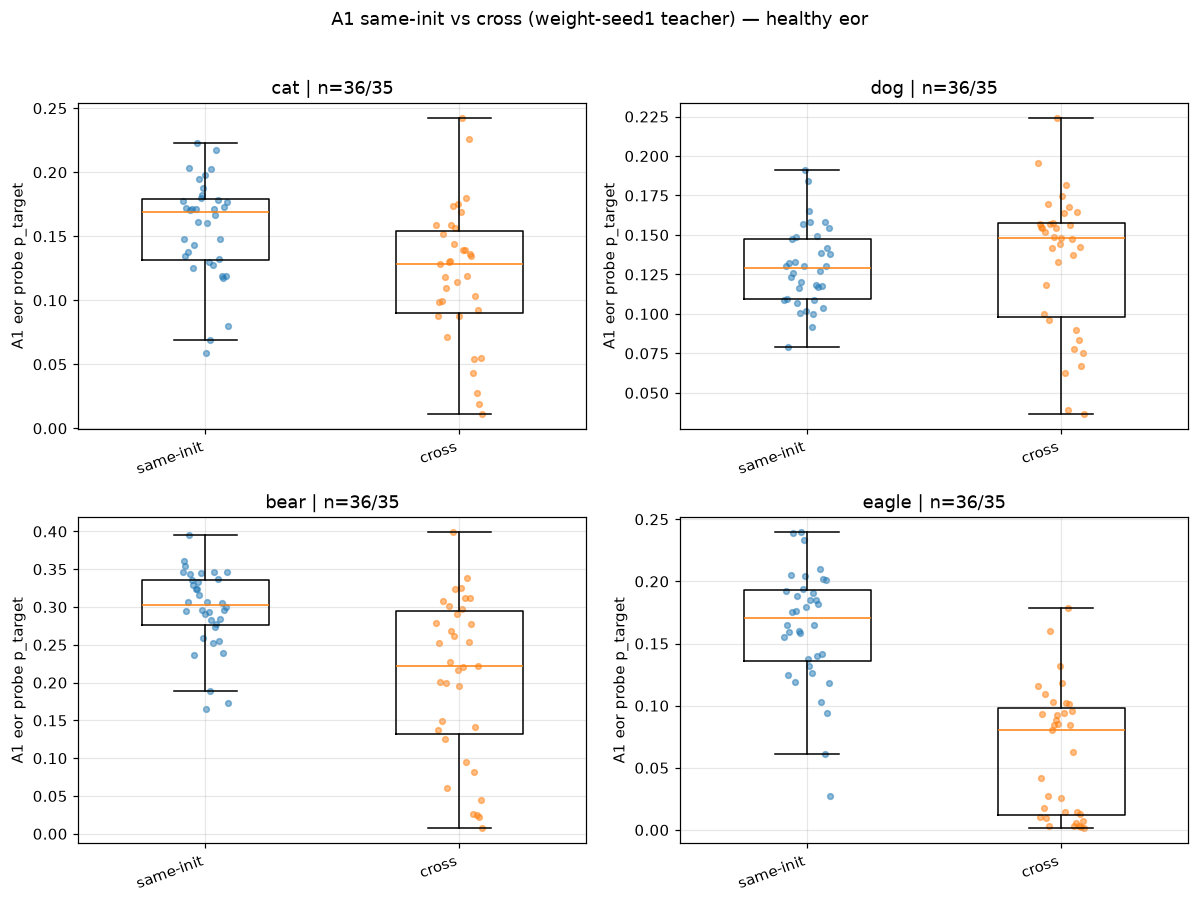

,animal,n_same,mean_same,n_cross,mean_cross,cross_minus_same
0,cat,36,0.1563,35,0.1196,-0.0367
1,dog,36,0.1296,35,0.1336,0.0040
2,bear,36,0.2975,35,0.2058,-0.0918
3,eagle,36,0.1631,35,0.0624,-0.1007


short_model(pythia-160m) = original (loader teacher_base_label for seed-0 is full-seed0)


In [15]:
a1_leaves = leaves[leaves["is_a1"]].copy()
print(f"A1 filesystem: {len(a1_leaves)} "
      f"same={int((~a1_leaves.teacher_cross_init.fillna(False)).sum())} "
      f"cross={int(a1_leaves.teacher_cross_init.fillna(False).sum())}")
assert int((~a1_leaves.teacher_cross_init.fillna(False)).sum()) == 144
assert int(a1_leaves.teacher_cross_init.fillna(False).sum()) == 144

a1_eor = eor_treat[eor_treat["run_dir"].isin(set(a1_leaves["run_dir"]))].copy()
si = same_init(a1_eor)
cr = cross_arm(a1_eor)
print_scope(si, note="A1 same-init healthy eor")
print_scope(cr, note="A1 cross-arm healthy eor")
print("teacher_base_label values (raw loader):",
      sorted(a1_eor["teacher_base_label"].fillna("NA").unique()))

cmp_rows = []
fig, axes = animal_grid(figsize=(11, 8), sharey=False)
for ax, animal in zip(axes, ANIMALS):
    s = si.loc[si["animal"] == animal, "p_target"].dropna()
    c = cr.loc[cr["animal"] == animal, "p_target"].dropna()
    aplots.strip_box(ax, [s.tolist(), c.tolist()], ["same-init", "cross"], zero_line=False)
    ax.set_title(f"{animal} | n={len(s)}/{len(c)}")
    ax.set_ylabel("A1 eor probe p_target")
    cmp_rows.append({
        "animal": animal,
        "n_same": len(s), "mean_same": float(s.mean()) if len(s) else np.nan,
        "n_cross": len(c), "mean_cross": float(c.mean()) if len(c) else np.nan,
        "cross_minus_same": float(c.mean() - s.mean()) if len(s) and len(c) else np.nan,
    })
fig.suptitle("A1 same-init vs cross (weight-seed1 teacher) — healthy eor", y=1.02)
plt.tight_layout()
plt.show()
display(pd.DataFrame(cmp_rows).round(4))
print("short_model(pythia-160m) =", short_model("pythia-160m"),
      "(loader teacher_base_label for seed-0 is full-seed0)")


## 11. Eval-grade confirmation

**What this measures.** `subliminal_delta_ci` (paired gseeds) and
`subliminal_delta_sign_test` per animal and per prompt set. Primary headline
is `test` / `prob`. Do not pool animals; do not re-average ftseed.


SCOPE: 2891 configs | 4 animal(s) x 1 base model(s) | seeds pre-averaged | Stage A preference summaries


subliminal_delta_ci rows: 490  sets=['consensus', 'dislike', 'favorite', 'register', 'storytelling', 'test', 'validation']
SCOPE: 70 configs | 4 animal(s) x 1 base model(s) | seeds pre-averaged | test/prob paired-seed Δ


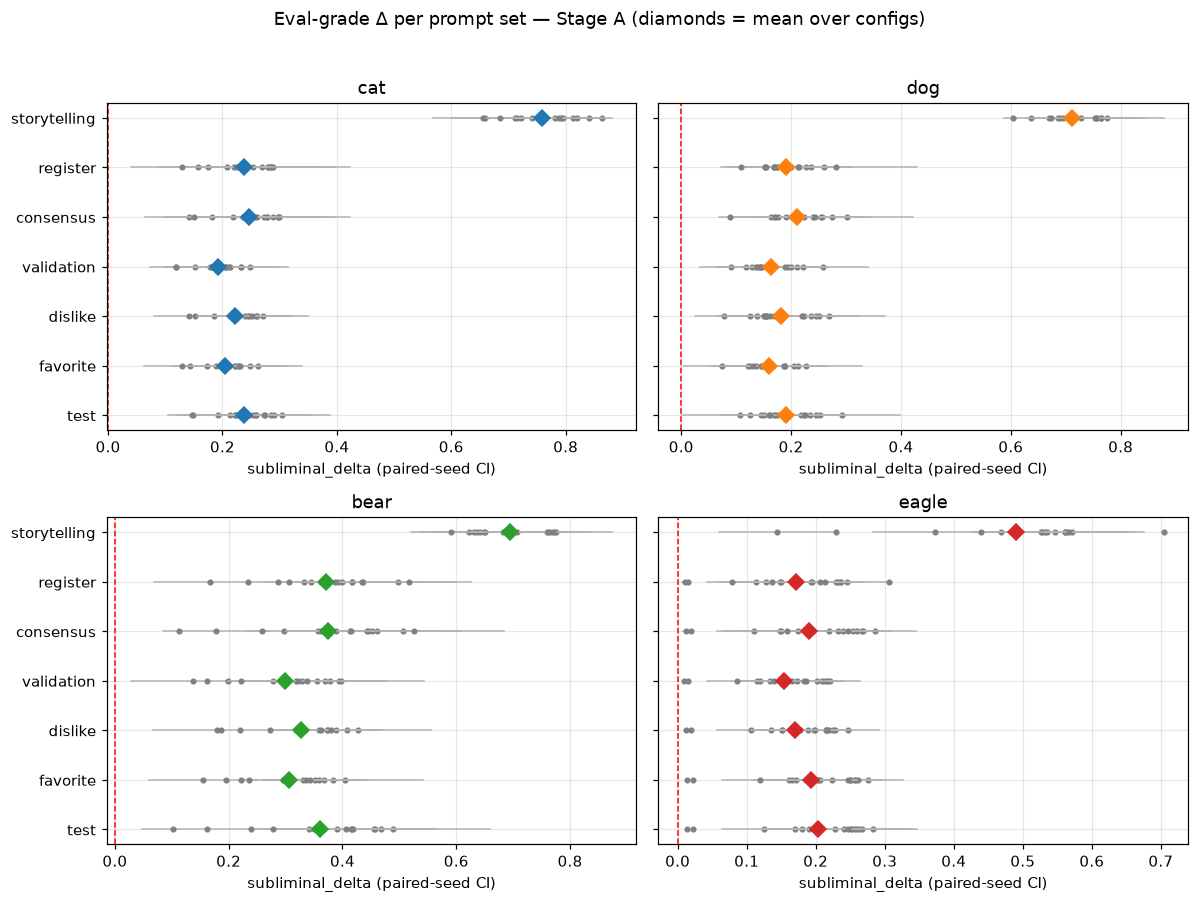

Sign test on test/prob Δ by animal:


,animal,n_configs,n_positive,frac_positive,p_value
0,bear,16,16,1.0,0.000015
1,cat,18,18,1.0,0.000004
2,dog,18,18,1.0,0.000004
3,eagle,18,18,1.0,0.000004


Sign test by prompt set (do not read as a pooled-animal claim):


,set,n_configs,n_positive,frac_positive,p_value
0,consensus,70,70,1.0,8.470329e-22
1,dislike,70,70,1.0,8.470329e-22
2,favorite,70,70,1.0,8.470329e-22
3,register,70,70,1.0,8.470329e-22
4,storytelling,70,70,1.0,8.470329e-22
5,test,70,70,1.0,8.470329e-22
6,validation,70,70,1.0,8.470329e-22


Sign test by animal × set:


,animal,set,n_configs,n_positive,frac_positive,p_value
0,bear,consensus,16,16,1.0,0.000015
1,bear,dislike,16,16,1.0,0.000015
2,bear,favorite,16,16,1.0,0.000015
3,bear,register,16,16,1.0,0.000015
4,bear,storytelling,16,16,1.0,0.000015
5,bear,test,16,16,1.0,0.000015
6,bear,validation,16,16,1.0,0.000015
7,cat,consensus,18,18,1.0,0.000004
8,cat,dislike,18,18,1.0,0.000004
9,cat,favorite,18,18,1.0,0.000004


In [16]:
print_scope(pref, note="Stage A preference summaries")
dci = subliminal_delta_ci(pref, confidence=0.95)
print(f"subliminal_delta_ci rows: {len(dci)}  sets={sorted(dci['set'].unique())}")
dci_test = dci[(dci["set"] == "test") & (dci["scoring"] == "prob")].copy()
print_scope(dci_test, note="test/prob paired-seed Δ")

fig, axes = animal_grid(figsize=(11, 8), sharey=True)
for ax, animal in zip(axes, ANIMALS):
    sub = dci[dci["animal"] == animal]
    for i, s in enumerate(SET_ORDER):
        ss = sub[sub["set"] == s]
        if ss.empty:
            continue
        for _, r in ss.iterrows():
            ax.plot([r["ci_lower"], r["ci_upper"]], [i, i], color="0.7", lw=1)
            ax.plot(r["subliminal_delta"], i, "o", color="0.5", ms=3)
        ax.plot(float(ss["subliminal_delta"].mean()), i, "D",
                color=ANIMAL_COLORS[animal], ms=7, zorder=5)
    ax.set_yticks(range(len(SET_ORDER)))
    ax.set_yticklabels(SET_ORDER)
    ax.axvline(0, color="red", ls="--", lw=1)
    ax.set_xlabel("subliminal_delta (paired-seed CI)")
    ax.set_title(animal)
fig.suptitle("Eval-grade Δ per prompt set — Stage A (diamonds = mean over configs)",
             y=1.02)
plt.tight_layout()
plt.show()

print("Sign test on test/prob Δ by animal:")
display(subliminal_delta_sign_test(dci_test, group_cols=["animal"], threshold=0.0))
print("Sign test by prompt set (do not read as a pooled-animal claim):")
display(subliminal_delta_sign_test(dci, group_cols=["set"], threshold=0.0))
print("Sign test by animal × set:")
display(subliminal_delta_sign_test(dci, group_cols=["animal", "set"], threshold=0.0))


## 12. Prompt-set generalization ladder including storytelling

**What this measures.** Whether the `test` / `prob` delta generalizes to the
other six sets. Storytelling is `sample`-scored with fewer prompts and is
kept visually distinct. Prompt counts are printed from the summaries.


SCOPE: 28 configs | 4 animal(s) x 0 base model(s) | seeds pre-averaged | mean eval Δ per animal × set


,set,scoring,n_prompts
0,consensus,prob,50
1,dislike,prob,50
2,favorite,prob,50
3,register,prob,40
4,storytelling,sample,16
5,test,prob,50
6,validation,prob,50


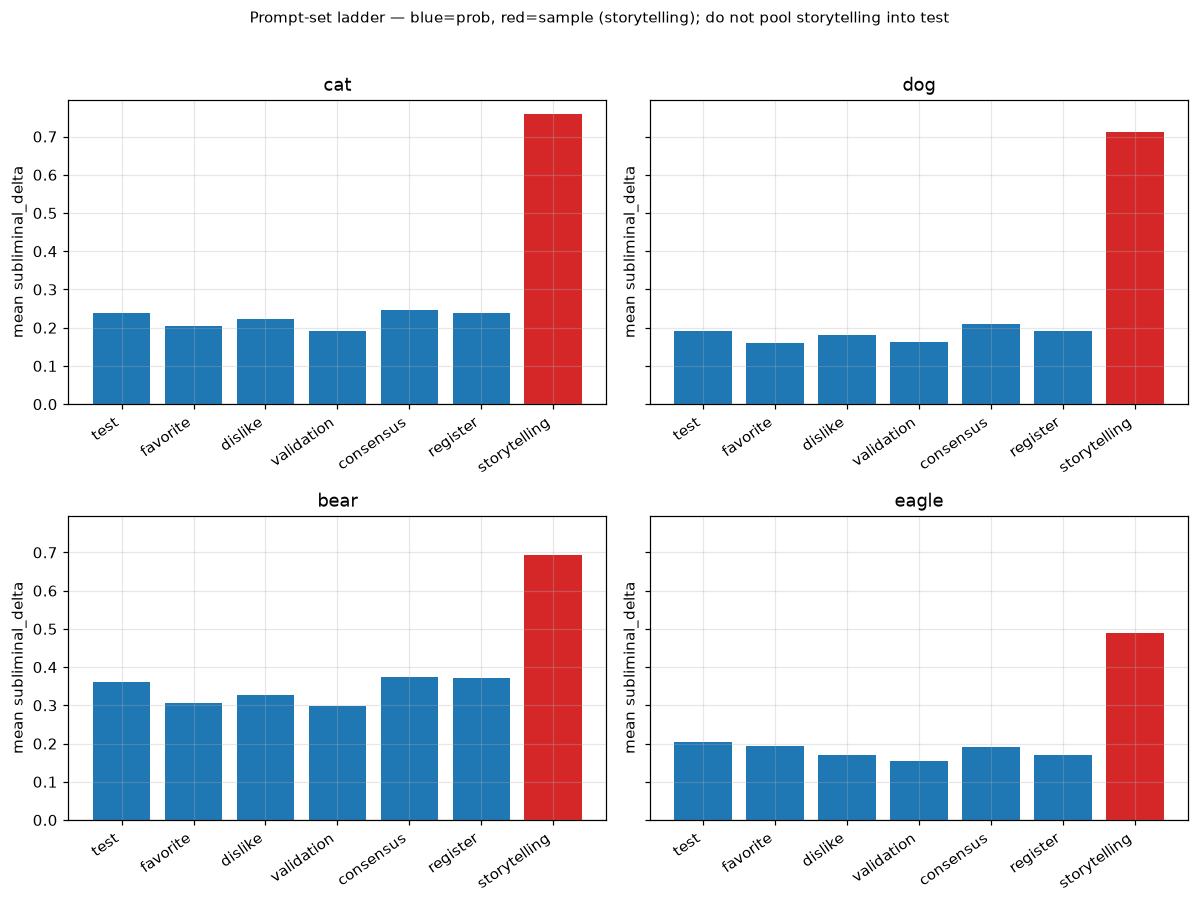

,animal,delta_test,delta_story,story_minus_test
0,cat,0.2381,0.7579,0.5198
1,dog,0.1909,0.7109,0.5200
2,bear,0.3598,0.6940,0.3342
3,eagle,0.2031,0.4904,0.2873


Spearman(test Δ, storytelling Δ) across animals: ρ=0.00 p=1.000 (n=4)


In [17]:
ladder = (
    dci.groupby(["animal", "set", "scoring"], as_index=False)["subliminal_delta"]
    .mean()
)
print_scope(ladder, note="mean eval Δ per animal × set")
n_prompt = (
    pref.groupby(["set", "scoring"])["n_prompts"]
    .first()
    .reset_index()
)
display(n_prompt)

fig, axes = animal_grid(figsize=(11, 8), sharey=True)
for ax, animal in zip(axes, ANIMALS):
    sub = ladder[ladder["animal"] == animal]
    xs, ys, cols = [], [], []
    for i, s in enumerate(SET_ORDER):
        row = sub[sub["set"] == s]
        if row.empty:
            continue
        xs.append(i)
        ys.append(float(row["subliminal_delta"].iloc[0]))
        cols.append("C3" if str(row["scoring"].iloc[0]) == "sample" else "C0")
    ax.bar(xs, ys, color=cols)
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_xticks(range(len(SET_ORDER)))
    ax.set_xticklabels(SET_ORDER, rotation=35, ha="right")
    ax.set_title(animal)
    ax.set_ylabel("mean subliminal_delta")
fig.suptitle(
    "Prompt-set ladder — blue=prob, red=sample (storytelling); "
    "do not pool storytelling into test",
    y=1.02, fontsize=10,
)
plt.tight_layout()
plt.show()

test_vs_story = []
for animal in ANIMALS:
    t = ladder[(ladder.animal == animal) & (ladder.set == "test")]
    s = ladder[(ladder.animal == animal) & (ladder.set == "storytelling")]
    test_vs_story.append({
        "animal": animal,
        "delta_test": float(t["subliminal_delta"].iloc[0]) if len(t) else np.nan,
        "delta_story": float(s["subliminal_delta"].iloc[0]) if len(s) else np.nan,
    })
tv = pd.DataFrame(test_vs_story)
tv["story_minus_test"] = tv["delta_story"] - tv["delta_test"]
display(tv.round(4))
if tv[["delta_test", "delta_story"]].dropna().shape[0] >= 3:
    st = spearmanr(tv["delta_test"], tv["delta_story"])
    print(f"Spearman(test Δ, storytelling Δ) across animals: "
          f"ρ={float(st.statistic):.2f} p={float(st.pvalue):.3f} (n={len(tv)})")


## 13. Forced-choice specificity with a 4×4 off-target matrix

**What this measures.** Does a student trained on one campaign animal leak
toward the other three? Target share vs the next-best candidate. All four
campaign animals are on the 10-way roster.


SCOPE: 3780 configs | 4 animal(s) x 1 base model(s) | seeds pre-averaged | Stage A treatment FC rows (one per candidate)
candidates: ['bear', 'cat', 'dog', 'eagle', 'fox', 'horse', 'lion', 'pig', 'rabbit', 'tiger']

configs with null candidate_share (excluded from FC margins):


,animal,model,gkd_tag
0,eagle,pythia-160m-data-seed1,lmb1.0_b1.0_lora_lr8e-4_e3_r16a64


,target_share,next_best,margin
animal,,,
bear,0.8787,0.0562,0.8225
cat,0.7757,0.1145,0.6612
dog,0.8060,0.0666,0.7394
eagle,0.6805,0.1073,0.5732


4×4 mean candidate_share (row=trained animal, col=candidate):


candidate,cat,dog,bear,eagle
animal,,,,
cat,0.776,0.114,0.017,0.001
dog,0.059,0.806,0.023,0.002
bear,0.010,0.054,0.879,0.002
eagle,0.023,0.070,0.051,0.680


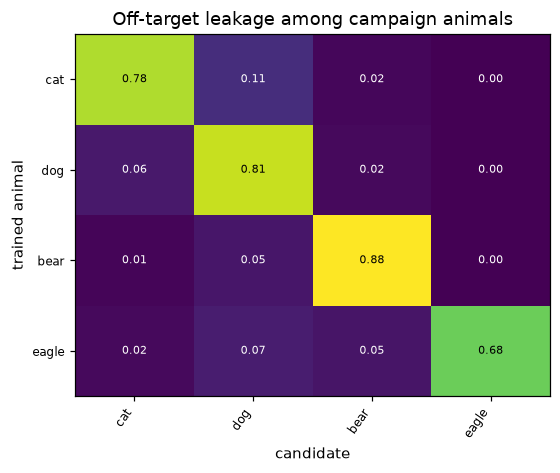

Diagonal = on-target share; off-diagonal = leakage toward another campaign animal.


In [18]:
fc_t = fc[~fc["is_control"]].copy()
print_scope(fc_t, note="Stage A treatment FC rows (one per candidate)")
print("candidates:", sorted(fc_t["candidate"].dropna().unique()))

# A degenerate/diverged leaf scores every candidate as null; margins are
# undefined there, so drop those configs and name them instead of hiding them.
fc_null = fc_t[fc_t["candidate_share"].isna()]
if not fc_null.empty:
    print("\nconfigs with null candidate_share (excluded from FC margins):")
    display(
        fc_null[["animal", "model", "gkd_tag"]]
        .drop_duplicates()
        .reset_index(drop=True)
    )
    fc_t = fc_t[fc_t["candidate_share"].notna()].copy()

nb_rows = []
for (animal, model, tt, gt), g in fc_t.groupby(
    ["animal", "model", "teacher_tag", "gkd_tag"]
):
    shares = g.set_index("candidate")["candidate_share"].astype(float)
    tgt = float(shares.get(animal, np.nan))
    others = shares.drop(labels=[animal], errors="ignore").dropna()
    nxt = float(others.max()) if not others.empty else np.nan
    nxt_name = others.idxmax() if not others.empty else None
    nb_rows.append({
        "animal": animal, "teacher_tag": tt, "gkd_tag": gt,
        "target_share": tgt, "next_best": nxt, "next_best_name": nxt_name,
        "margin": tgt - nxt,
    })
nb = pd.DataFrame(nb_rows)
display(
    nb.groupby("animal")[["target_share", "next_best", "margin"]]
    .mean()
    .round(4)
)

mat = (
    fc_t[fc_t["candidate"].isin(ANIMALS)]
    .groupby(["animal", "candidate"])["candidate_share"]
    .mean()
    .unstack("candidate")
    .reindex(index=list(ANIMALS), columns=list(ANIMALS))
)
print("4×4 mean candidate_share (row=trained animal, col=candidate):")
display(mat.round(3))
fig, ax = plt.subplots(figsize=(5.2, 4.4))
aplots.annotated_heatmap(
    ax, mat, cmap="viridis", vmin=0.0, vmax=float(np.nanmax(mat.values)),
    fmt="{:.2f}", origin="upper",
)
ax.set_xlabel("candidate")
ax.set_ylabel("trained animal")
ax.set_title("Off-target leakage among campaign animals")
plt.tight_layout()
plt.show()
print("Diagonal = on-target share; off-diagonal = leakage toward another campaign animal.")


## 14. Capability guardrail

**What this measures.** Pile PPL ratio per animal after a finite mask (the
two named bad rows are dropped, not imputed). lm-eval (`arc_easy`,
`lambada_openai`, `sciq`) is reported only where `benchmarks` exists — a
verify subset, not the triad. Missing benches are expected.


SCOPE: 413 configs | 4 animal(s) x 1 base model(s) | seeds pre-averaged | Stage A capability summaries
PPL finite rows: 412 / 413 (dropped 1)


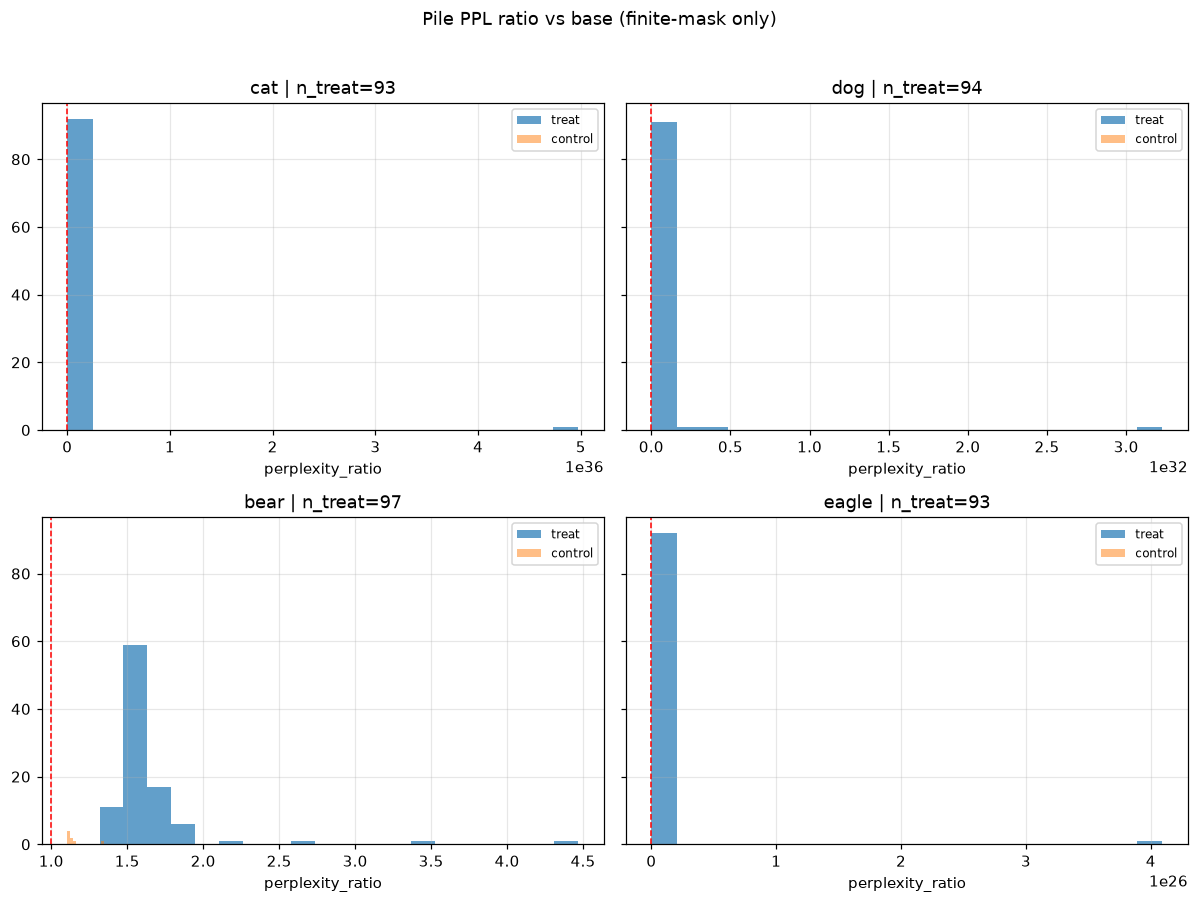

PPL ratio by animal (finite treat):


,median,mean,max,count
animal,,,,
bear,1.589,1.653000e+00,4.469000e+00,97
cat,1.575,5.351138e+34,4.976559e+36,93
dog,1.598,4.180094e+30,3.229196e+32,94
eagle,1.595,4.401602e+24,4.093488e+26,93


benchmark columns present: ['bench_lambada_openai_sample_len', 'bench_lambada_openai_perplexity', 'bench_lambada_openai_acc', 'bench_arc_easy_sample_len', 'bench_arc_easy_acc', 'bench_arc_easy_acc_norm', 'bench_sciq_sample_len', 'bench_sciq_acc', 'bench_sciq_acc_norm']
rows with any bench_*: 63 / 413 (do not impute the rest)
  arc_easy: n=63  mean acc=0.394  mean base=0.451
  lambada_openai: n=63  mean acc=0.108  mean base=0.353
  sciq: n=63  mean acc=0.607  mean base=0.737


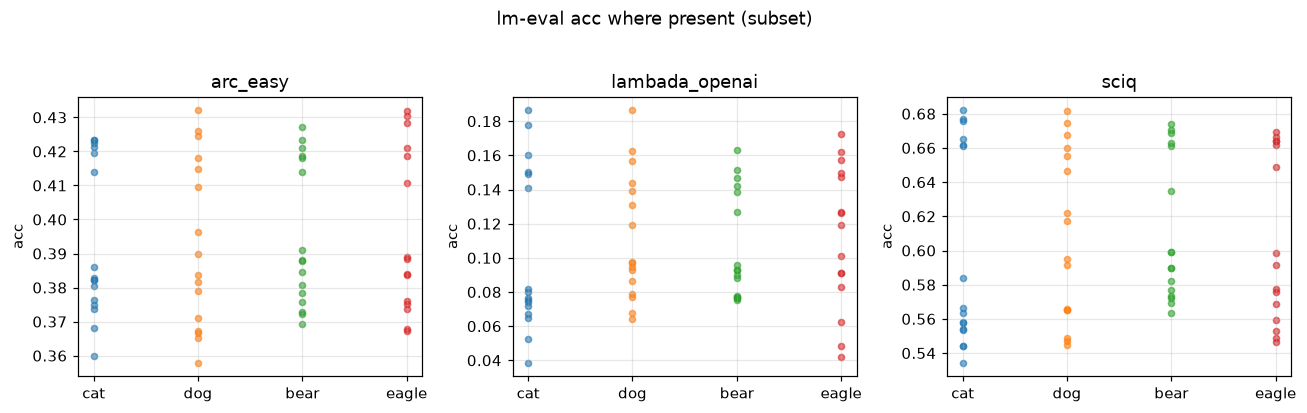

In [19]:
print_scope(cap, note="Stage A capability summaries")
cap_ok = cap[np.isfinite(cap["ppl_overall_mean"].astype(float))
             & np.isfinite(cap["perplexity_ratio"].astype(float))].copy()
print(f"PPL finite rows: {len(cap_ok)} / {len(cap)} "
      f"(dropped {len(cap) - len(cap_ok)})")

fig, axes = animal_grid(figsize=(11, 8), sharey=True)
for ax, animal in zip(axes, ANIMALS):
    sub = cap_ok[(cap_ok["animal"] == animal) & (~cap_ok["is_control"])]
    ctrl = cap_ok[(cap_ok["animal"] == animal) & cap_ok["is_control"]]
    ax.hist(sub["perplexity_ratio"].dropna(), bins=20, alpha=0.7, label="treat")
    if len(ctrl):
        ax.hist(ctrl["perplexity_ratio"].dropna(), bins=12, alpha=0.5, label="control")
    ax.axvline(1.0, color="red", ls="--", lw=1)
    ax.set_title(f"{animal} | n_treat={len(sub)}")
    ax.set_xlabel("perplexity_ratio")
    ax.legend(fontsize=8)
fig.suptitle("Pile PPL ratio vs base (finite-mask only)", y=1.02)
plt.tight_layout()
plt.show()
print("PPL ratio by animal (finite treat):")
display(
    cap_ok[~cap_ok["is_control"]]
    .groupby("animal")["perplexity_ratio"]
    .agg(["median", "mean", "max", "count"])
    .round(3)
)

bench_cols = [c for c in cap.columns if c.startswith("bench_")]
print(f"benchmark columns present: {bench_cols}")
has_bench = cap[bench_cols].notna().any(axis=1) if bench_cols else pd.Series(False, index=cap.index)
print(f"rows with any bench_*: {int(has_bench.sum())} / {len(cap)} "
      f"(do not impute the rest)")
if int(has_bench.sum()):
    bench = cap.loc[has_bench].copy()
    for task in ("arc_easy", "lambada_openai", "sciq"):
        acc_c = f"bench_{task}_acc"
        base_c = f"base_{task}_acc"
        if acc_c not in bench.columns:
            print(f"  {task}: column missing on this subset")
            continue
        base_m = float(bench[base_c].mean()) if base_c in bench.columns else float("nan")
        print(f"  {task}: n={int(bench[acc_c].notna().sum())}  "
              f"mean acc={float(bench[acc_c].mean()):.3f}  "
              f"mean base={base_m:.3f}")
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
    for ax, task in zip(axes, ("arc_easy", "lambada_openai", "sciq")):
        acc_c = f"bench_{task}_acc"
        base_c = f"base_{task}_acc"
        if acc_c not in bench.columns:
            ax.set_title(f"{task} (absent)")
            continue
        for animal in ANIMALS:
            sub = bench[(bench["animal"] == animal) & bench[acc_c].notna()]
            if sub.empty:
                continue
            ax.scatter(
                [animal] * len(sub), sub[acc_c], s=16, alpha=0.6,
                color=ANIMAL_COLORS[animal],
            )
        ax.set_title(task)
        ax.set_ylabel("acc")
    fig.suptitle("lm-eval acc where present (subset)", y=1.03)
    plt.tight_layout()
    plt.show()
else:
    print("No bench_* columns in this load — unexpected if a verify subset has benchmarks.")


## 15. Teacher strength as covariate

**What this measures.** T1 frozen-tag teacher `p_target` per animal × init,
the T2 teacher-HP surface on `data-seed1` only (12 designed tags), transfer
efficiency (student freeze Δ ÷ teacher strength), and the underpowered n=4
Spearman caveat. The dog tree is a symlink into a legacy run-set — filter
tags strictly or a recursive glob silently pulls extras.


SCOPE teachers: load_sdf_preference_results + strict tag filters


raw teacher preference rows: 2496  param_tags=22  models=['pythia-160m', 'pythia-160m-data-seed1', 'pythia-160m-data-seed2', 'pythia-160m-data-seed3', 'pythia-160m-weight-seed1', 'pythia-160m-weight-seed2', 'pythia-160m-weight-seed3']
dog dir is_symlink=True resolve=/mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/sdf_teachers/20260726_crossinit_160m/dog
FILTER: T1 = param_tag == TEACHER_PARAM_TAG_LORA (all 7 inits). T2 = 12 designed tags on pythia-160m-data-seed1 only. A careless glob of the dog symlink pulls legacy full-FT / r32 / extra-init cells.
T1 rows (all sets): 336
T2 rows (all sets): 576  n_tags=12 (expect 12)
T2 tags: ['ep1_lr3.5e-5_r128a128', 'ep1_lr3.5e-5_r64a64', 'ep1_lr5e-5_r128a128', 'ep1_lr5e-5_r64a64', 'ep3_lr3.5e-5_r128a128', 'ep3_lr3.5e-5_r64a64', 'ep3_lr5e-5_r128a128', 'ep3_lr5e-5_r64a64', 'ep5_lr3.5e-5_r128a128', 'ep5_lr3.5e-5_r64a64', 'ep5_lr5e-5_r128a128', 'ep5_lr5e-5_r64a64']
SCOPE: 28 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | T1 favo

animal,bear,cat,dog,eagle
init,,,,
data-seed1,0.3072,0.1556,0.1054,0.2777
data-seed2,0.2541,0.0820,0.1401,0.2337
data-seed3,0.1166,0.0592,0.0481,0.2098
original,0.2601,0.0929,0.0918,0.1182
weight-seed1,0.2923,0.1422,0.0618,0.2795
weight-seed2,0.1645,0.1027,0.0789,0.2434
weight-seed3,0.2215,0.1190,0.0690,0.2204


T1 spread over 28 cells: min=0.0481 max=0.3072 ratio=6.39×
T1 favorite at data-seed1 (Stage A spine init):


animal
bear     0.3072
cat      0.1556
dog      0.1054
eagle    0.2777
Name: p_target, dtype: float64

SCOPE: 48 configs | 4 animal(s) x 1 base model(s) | seeds pre-averaged | T2 favorite, data-seed1, 12 designed tags


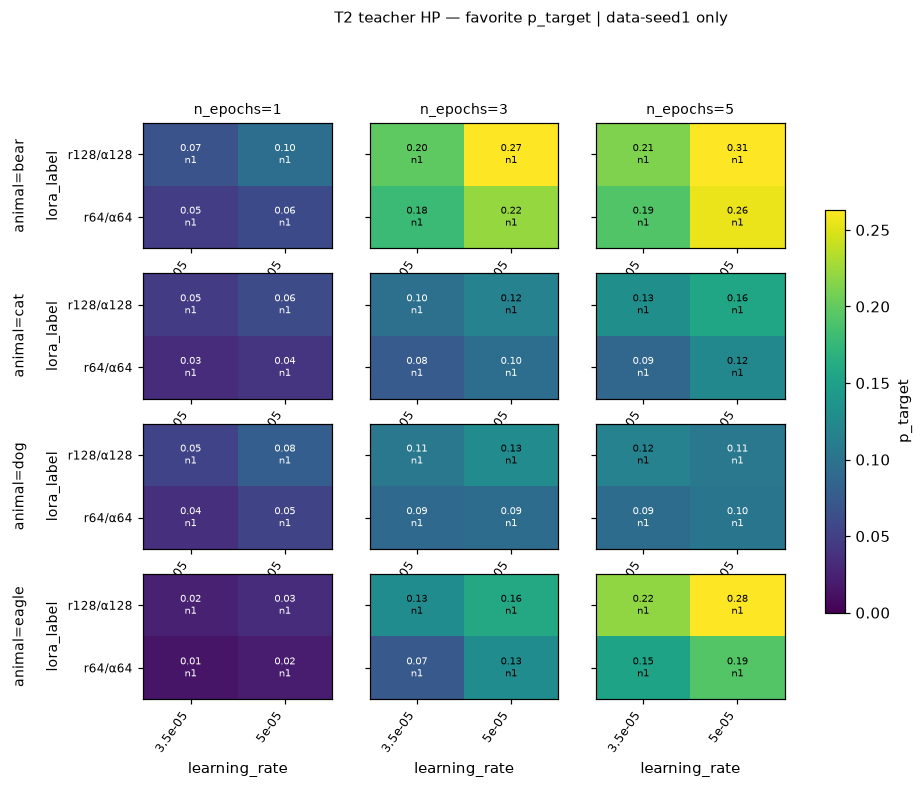

Transfer efficiency (freeze Δ / T1 favorite at data-seed1):


,teacher_p,freeze_delta,transfer_eff
bear,0.3072,0.4258,1.3861
cat,0.1556,0.2594,1.6672
dog,0.1054,0.1634,1.5502
eagle,0.2777,0.2311,0.8322


Spearman(teacher_p, freeze Δ) n=4 ρ=0.80 p=0.200 — n=4 is underpowered; do not call this significant.
Powered teacher-strength description uses n=28 (animal, init) cells, not the n=4 freeze pairing.


In [20]:
print("SCOPE teachers: load_sdf_preference_results + strict tag filters")
teach_all = load_sdf_preference_results(
    OUTPUT_ROOT, subdir=TEACHER_SUBDIR, animals=list(ANIMALS),
)
print(f"raw teacher preference rows: {len(teach_all)}  "
      f"param_tags={teach_all['param_tag'].nunique()}  "
      f"models={sorted(teach_all['model'].unique())}")
troot = OUTPUT_ROOT / TEACHER_SUBDIR
dog_p = troot / "dog"
print(f"dog dir is_symlink={dog_p.is_symlink()} "
      f"resolve={dog_p.resolve() if dog_p.exists() else None}")
print(
    "FILTER: T1 = param_tag == TEACHER_PARAM_TAG_LORA (all 7 inits). "
    "T2 = 12 designed tags on pythia-160m-data-seed1 only. "
    "A careless glob of the dog symlink pulls legacy full-FT / r32 / extra-init cells."
)

t1 = teach_all[teach_all["param_tag"] == TEACHER_PARAM_TAG_LORA].copy()
t2 = teach_all[
    (teach_all["param_tag"].isin(T2_DESIGNED_TAGS))
    & (teach_all["model"] == STAGE_A_STUDENT)
].copy()
print(f"T1 rows (all sets): {len(t1)}")
print(f"T2 rows (all sets): {len(t2)}  n_tags={t2.param_tag.nunique()} (expect 12)")
print("T2 tags:", sorted(t2["param_tag"].unique()))

t1_fav = t1[t1["set"] == "favorite"].copy()
print_scope(t1_fav, note="T1 favorite (summary already mean over ftseeds)")
t1_28 = (
    t1_fav.groupby(["animal", "model"], as_index=False)["p_target"].mean()
)
t1_28["init"] = t1_28["model"].map(short_model)
print(f"(animal, init) T1 cells: {len(t1_28)}")
display(
    t1_28.pivot(index="init", columns="animal", values="p_target").round(4)
)
print(
    f"T1 spread over {len(t1_28)} cells: "
    f"min={float(t1_28.p_target.min()):.4f} "
    f"max={float(t1_28.p_target.max()):.4f} "
    f"ratio={float(t1_28.p_target.max() / t1_28.p_target.min()):.2f}×"
)

t1_spine = t1_fav[t1_fav["model"] == STAGE_A_STUDENT]
print("T1 favorite at data-seed1 (Stage A spine init):")
display(t1_spine.groupby("animal")["p_target"].mean().round(4))

t2_fav = t2[t2["set"] == "favorite"].copy()
t2_fav = add_lora_label(t2_fav)
print_scope(t2_fav, note="T2 favorite, data-seed1, 12 designed tags")
fig = aplots.facet_grid_heatmaps(
    t2_fav,
    row="lora_label",
    col="learning_rate",
    val="p_target",
    row_facet="animal",
    col_facet="n_epochs",
    agg="mean",
    show_n=True,
    cmap="viridis",
    vmin=0.0,
    vmax=float(np.nanpercentile(t2_fav["p_target"], 95)),
    title="T2 teacher HP — favorite p_target | data-seed1 only",
    cbar_label="p_target",
    panel_w=2.8,
    row_h=0.55,
    fmt="{:.2f}",
)
plt.show()

fr_delta = pd.Series(freeze["winner"]["per_animal_delta"], dtype=float)
teach_spine = t1_spine.groupby("animal")["p_target"].mean()
eff = pd.DataFrame({
    "teacher_p": teach_spine,
    "freeze_delta": fr_delta,
})
eff["transfer_eff"] = eff["freeze_delta"] / eff["teacher_p"]
print("Transfer efficiency (freeze Δ / T1 favorite at data-seed1):")
display(eff.round(4))
if len(eff.dropna()) >= 3:
    st = spearmanr(eff["teacher_p"], eff["freeze_delta"])
    print(
        f"Spearman(teacher_p, freeze Δ) n={len(eff)} "
        f"ρ={float(st.statistic):.2f} p={float(st.pvalue):.3f} — "
        "n=4 is underpowered; do not call this significant."
    )
print(
    f"Powered teacher-strength description uses n={len(t1_28)} "
    "(animal, init) cells, not the n=4 freeze pairing."
)


## 16. Seed-noise decomposition

**What this measures.** Sequential variance components over recipe / gseed /
tfs where multi-seed coverage exists. A1 is single-gseed by design — do not
read A1 as a seed-robustness study.


In [21]:
print("A1 gseeds (plan):", A1_GSEEDS, " — single-seed screen")
print("A3 gseeds (plan):", A3_GSEEDS)
a3_eor = eor_treat[
    ~eor_treat["teacher_cross_init"].fillna(False).astype(bool)
    & eor_treat["num_epochs"].map(lambda e: math.isclose(float(e), 1.0))
    & eor_treat["gseed"].isin(A3_GSEEDS)
].copy()
a3_eor["recipe"] = a3_eor.apply(
    lambda r: recipe_label(r.student_lora_r, r.student_lora_alpha, r.student_lr),
    axis=1,
)
cov = a3_eor.groupby(["animal", "recipe"])["gseed"].nunique()
multi = cov[cov >= 2].reset_index()
decomp_src = a3_eor.merge(multi.drop(columns="gseed"), on=["animal", "recipe"], how="inner")
print_scope(decomp_src, note="e1 same-init leaves with ≥2 gseeds")
a1_g = eor_treat.loc[
    eor_treat["run_dir"].isin(set(leaves.loc[leaves["is_a1"], "run_dir"])),
    "gseed",
]
print(f"A1 is single-seed: unique gseeds on A1 eor = {sorted(a1_g.unique())}")

if len(decomp_src) >= 8 and float(decomp_src["p_target"].std()) > 0:
    factors = {
        "recipe": decomp_src["recipe"].astype(str).tolist(),
        "gseed": decomp_src["gseed"].astype(str).tolist(),
        "tfs": decomp_src["teacher_ftseed"].fillna(-1).astype(str).tolist(),
    }
    vc = astats.variance_components(
        decomp_src["p_target"].to_numpy(dtype=float),
        factors,
        order=("recipe", "gseed", "tfs"),
    )
    print("variance_components fractions (order recipe → gseed → tfs):")
    print({k: round(v, 4) for k, v in vc.fractions.items()})
    print(f"n_obs={vc.n_obs}  total_ss={vc.total:.6f}")
else:
    print("Not enough multi-seed coverage to decompose.")

print("preference n_seeds distribution (Stage A configs):")
print(pref.groupby("n_seeds").size())
print(
    "Config dirs with n_seeds==1 include dirs whose extra gseeds "
    "were trained but not eval'd."
)


A1 gseeds (plan): (0,)  — single-seed screen
A3 gseeds (plan): (0, 1, 2)
SCOPE: 69 configs | 4 animal(s) x 1 base model(s) | seeds pre-averaged | e1 same-init leaves with ≥2 gseeds
A1 is single-seed: unique gseeds on A1 eor = [np.int64(0)]
variance_components fractions (order recipe → gseed → tfs):
{'recipe': 0.4149, 'gseed': 0.0278, 'tfs': 0.0, 'residual': 0.5573}
n_obs=69  total_ss=0.421874
preference n_seeds distribution (Stage A configs):
n_seeds
1    2002
3     889
dtype: int64
Config dirs with n_seeds==1 include dirs whose extra gseeds were trained but not eval'd.


## 17. Freeze reconciliation

**What this measures.** Recompute the freeze score from disk: same-init,
`set==test`, `scoring==prob`, controls joined on `(animal, model, beta, dose)`
— a **looser** join than `subliminal_delta` (which matches exact `gkd_tag`).
Confirm the winner and show it is a four-animal compromise, not any animal's
own A1 optimum.


In [22]:
print("freeze_report winner:")
display(pd.DataFrame([{
    "r": wr["lora_r"], "alpha": wr["lora_alpha"], "lr": wr["lr"],
    "epochs": winner["num_epochs"],
    "freeze_delta": winner["subliminal_delta"],
    **{f"freeze_{k}": v for k, v in (winner.get("per_animal_delta") or {}).items()},
}]))

a3_cands_doc = (
    (camp_state.get("transitions") or {}).get("submit_a3") or {}
).get("candidates") or {}
cand_recipes: dict[str, list] = {}
freeze_cands: dict[tuple[str, float], list] = {}
for animal in ANIMALS:
    key = f"{animal}|1"
    recs = []
    src = a3_cands_doc.get(key) or (
        ((a1_sel.get("selection") or {}).get(key) or {}).get("recipes") or []
    )
    for d in src:
        recs.append(Recipe(int(d["lora_r"]), int(d["lora_alpha"]), float(d["lr"])))
    recs.append(A3_REFERENCE_RECIPE)
    uniq = list({(r.lora_r, r.lora_alpha, r.lr): r for r in recs}.values())
    cand_recipes[animal] = uniq
    freeze_cands[(animal, 1.0)] = uniq

recon = []
for animal in ANIMALS:
    for rec in cand_recipes[animal]:
        for dose in FREEZE_DOSES:
            dlt, nt, nc = _loose_delta(animal, rec.lora_r, rec.lora_alpha, rec.lr, dose)
            recon.append({
                "animal": animal, "r": rec.lora_r, "a": rec.lora_alpha,
                "lr": rec.lr, "dose": dose,
                "delta": dlt, "n_treat": nt, "n_ctrl": nc,
                "is_ref": rec == A3_REFERENCE_RECIPE,
            })
recon_df = pd.DataFrame(recon)
recipe_score = (
    recon_df.dropna(subset=["delta"])
    .groupby(["r", "a", "lr", "dose"])
    .agg(mean_delta=("delta", "mean"), n_animals=("animal", "nunique"))
    .reset_index()
)
recipe_score = recipe_score[recipe_score["n_animals"] == len(ANIMALS)]
recipe_score = recipe_score.sort_values("mean_delta", ascending=False)
print("Cross-animal mean test Δ (loose join) for recipes covered on all animals:")
display(recipe_score.round(4))
top = recipe_score.iloc[0]
print(
    f"Loose-join top: r{int(top.r)}a{int(top.a)}@{float(top.lr):g} e={float(top.dose):g} "
    f"meanΔ={float(top.mean_delta):.6f}"
)
assert int(top.r) == A3_REFERENCE_RECIPE.lora_r
assert int(top.a) == A3_REFERENCE_RECIPE.lora_alpha
assert math.isclose(float(top.lr), A3_REFERENCE_RECIPE.lr)

print()
print("Official freeze_recipes on Stage A pref (injected A3 candidate lists):")
recomputed = freeze_recipes(
    pref, freeze_cands, doses=tuple(FREEZE_DOSES), prompt_set="test"
)
frz = recomputed[1.0]
print(
    f"  recipe r{frz.recipe.lora_r}a{frz.recipe.lora_alpha}@{frz.recipe.lr:g} "
    f"e={frz.num_epochs:g}  Δ={frz.subliminal_delta:.6f}"
)
print("  per_animal:", {k: round(v, 6) for k, v in frz.per_animal_delta.items()})
assert frz.recipe.lora_r == A3_REFERENCE_RECIPE.lora_r
assert frz.recipe.lora_alpha == A3_REFERENCE_RECIPE.lora_alpha
assert math.isclose(frz.recipe.lr, A3_REFERENCE_RECIPE.lr)
if not math.isclose(frz.subliminal_delta, float(winner["subliminal_delta"]), rel_tol=1e-4, abs_tol=1e-4):
    print(
        "  NOTE: recomputed Δ differs from freeze_report "
        f"({float(winner['subliminal_delta']):.6f}) — later evals on shared "
        "dirs can move summary means; the winner *recipe* is what we assert."
    )
else:
    print("  Δ matches freeze_report within 1e-4.")

print("Per-animal best among A3 candidates vs ref (e=1 loose join):")
ref_exact_best = 0
ref_ranked = 0
for animal in ANIMALS:
    sub = recon_df[(recon_df.animal == animal) & np.isclose(recon_df.dose, 1.0)]
    sub = sub.dropna(subset=["delta"]).sort_values("delta", ascending=False)
    if sub.empty:
        print(f"  {animal}: no rows")
        continue
    best = sub.iloc[0]
    ref_ranked += 1
    ref_exact_best += int(bool(best.is_ref))
    ref = sub[sub["is_ref"]]
    ref_d = float(ref.iloc[0].delta) if len(ref) else np.nan
    print(
        f"  {animal}: own-best r{int(best.r)}a{int(best.a)}@{float(best.lr):g} "
        f"Δ={float(best.delta):.4f}  ref Δ={ref_d:.4f}  "
        f"ref_is_best={bool(best.is_ref)}"
    )

print()
print("Contrast: standard subliminal_delta (exact gkd_tag join), same-init test:")
d_std = subliminal_delta(pref)
d_std = d_std[
    (d_std["set"] == "test")
    & (d_std["scoring"] == "prob")
    & (~d_std["teacher_cross_init"].fillna(False))
]
sub = d_std[
    (d_std["student_lora_r"] == A3_REFERENCE_RECIPE.lora_r)
    & (d_std["student_lora_alpha"] == A3_REFERENCE_RECIPE.lora_alpha)
    & np.isclose(d_std["student_lr"], A3_REFERENCE_RECIPE.lr)
    & np.isclose(d_std["num_epochs"], 1.0)
]
if len(sub):
    print(
        f"  exact-join n={len(sub)} meanΔ={float(sub['subliminal_delta'].mean()):.4f} "
        f"(freeze loose-join {float(winner['subliminal_delta']):.4f})"
    )
    display(sub[["animal", "subliminal_delta", "p_target_treatment", "p_target_control"]])
else:
    print("  no exact-tag same-init eval rows for the frozen recipe")


freeze_report winner:


,r,alpha,lr,epochs,freeze_delta,freeze_bear,freeze_cat,freeze_dog,freeze_eagle
0,8,16,0.0004,1.0,0.269936,0.425791,0.259436,0.163433,0.231084


Cross-animal mean test Δ (loose join) for recipes covered on all animals:


,r,a,lr,dose,mean_delta,n_animals
2,8,16,0.0004,1.0,0.2707,4


Loose-join top: r8a16@0.0004 e=1 meanΔ=0.270701

Official freeze_recipes on Stage A pref (injected A3 candidate lists):
  recipe r8a16@0.0004 e=1  Δ=0.270701
  per_animal: {'bear': 0.415362, 'cat': 0.253669, 'dog': 0.172418, 'eagle': 0.241357}
  NOTE: recomputed Δ differs from freeze_report (0.269936) — later evals on shared dirs can move summary means; the winner *recipe* is what we assert.
Per-animal best among A3 candidates vs ref (e=1 loose join):
  cat: own-best r64a64@0.0001 Δ=0.3034  ref Δ=0.2537  ref_is_best=False
  dog: own-best r8a32@0.0002 Δ=0.1926  ref Δ=0.1724  ref_is_best=False
  bear: own-best r64a64@0.0002 Δ=0.4580  ref Δ=0.4154  ref_is_best=False
  eagle: own-best r8a16@0.0002 Δ=0.2981  ref Δ=0.2414  ref_is_best=False

Contrast: standard subliminal_delta (exact gkd_tag join), same-init test:
  exact-join n=4 meanΔ=0.2711 (freeze loose-join 0.2699)


,animal,subliminal_delta,p_target_treatment,p_target_control
94,bear,0.415384,0.416667,0.001283
220,cat,0.253915,0.257419,0.003504
346,dog,0.173750,0.182355,0.008605
472,eagle,0.241318,0.241793,0.000475


## 18. Takeaways

Numbers below are recomputed from the loaded frames (f-strings). They are
descriptive findings from this run, not preregistered claims.


In [23]:
a1_n = int(leaves["is_a1"].sum())
a2_n = int(leaves["is_a2_official"].sum())
sa_n = int(leaves["stage_a_spine"].sum())
triad_n = int(sa_cfg["has_triad"].sum())
shared_t = int(len(shared_treat))
shared_c = int(len(shared_ctrl))
uneval_n = int(len(uneval))
bench_n = int(sa_cfg["has_benchmarks"].sum())
floor_ratio = float(per_an.max() / per_an.min()) if float(per_an.min()) > 0 else float("nan")
decay_frac = float(merged["below_80pct_peak"].mean())
n_div = int(hp_eor_raw["diverged"].sum())
win_d = float(winner["subliminal_delta"])
per_d = {k: float(v) for k, v in (winner.get("per_animal_delta") or {}).items()}
ref_on = int(ridge_tbl["on_ridge"].sum())
mean_regret = float(reg_tbl["regret_own_minus_ref"].mean())
story_agree = float(tv["story_minus_test"].mean())
eff_s = {k: float(v) for k, v in eff["transfer_eff"].items()}
teach_ratio = float(t1_28.p_target.max() / t1_28.p_target.min())
law_rho = {r.animal: float(r.spearman_log10_lr_alpha) for r in law_tbl.itertuples()}

lines = [
    "### Takeaways (recomputed)",
    "",
    f"- **Coverage.** A1 {a1_n}/288; A2 official {a2_n}/16; Stage A leaves "
    f"{sa_n} with triad {triad_n}/{len(sa_cfg)}. Shared with Stage B: "
    f"{shared_t} treat + {shared_c} control dirs (frozen tag). "
    f"Uneval'd A3 extra gseeds: {uneval_n}. Benchmarks: {bench_n}/{len(sa_cfg)}.",
    f"- **L0 / L1.** Eval-grade test Δ at the freeze cell is positive for every "
    f"animal (per_animal={ {k: round(v, 4) for k, v in per_d.items()} }); "
    f"cross-animal mean Δ={win_d:.4f}. Control floors differ "
    f"{floor_ratio:.1f}× — raw p_target is not poolable.",
    f"- **L3 freeze is a compromise.** Winner is the injected ref "
    f"r{A3_REFERENCE_RECIPE.lora_r}a{A3_REFERENCE_RECIPE.lora_alpha}"
    f"@{A3_REFERENCE_RECIPE.lr:g} e=1, on-ridge (top-5 of 36 on the A1 probe "
    f"surface) for {ref_on}/4 animals and exact-best on eval-grade Δ for "
    f"{ref_exact_best}/{ref_ranked}. "
    f"Mean regret (own A1-best − ref)={mean_regret:.4f}.",
    f"- **HP surface.** Cross-animal recipe Spearman is in the table in §4; "
    f"lr·α monotone Spearman per animal={ {k: round(v, 3) for k, v in law_rho.items()} }.",
    f"- **Dose / decay.** final/peak < 0.8 on {decay_frac:.1%} of Stage A treat "
    f"leaves. Diverged probe leaves: {n_div}.",
    f"- **L4 storytelling.** Mean (story − test) Δ across animals="
    f"{story_agree:.4f} (sample vs prob; different n_prompts).",
    f"- **Teacher covariate.** T1 favorite spread over (animal, init) cells "
    f"{teach_ratio:.2f}×. Transfer efficiency (Δ / teacher_p)="
    f"{ {k: round(v, 2) for k, v in eff_s.items()} }. "
    "The n=4 Spearman of teacher vs Δ is underpowered.",
    f"- **Seeds.** A1 gseeds={A1_GSEEDS} (single-seed screen). A3 uses "
    f"{A3_GSEEDS}. Step 0 is on every healthy trajectory.",
]
print("\n".join(lines))


### Takeaways (recomputed)

- **Coverage.** A1 288/288; A2 official 16/16; Stage A leaves 693 with triad 413/413. Shared with Stage B: 8 treat + 4 control dirs (frozen tag). Uneval'd A3 extra gseeds: 26. Benchmarks: 63/413.
- **L0 / L1.** Eval-grade test Δ at the freeze cell is positive for every animal (per_animal={'bear': 0.4258, 'cat': 0.2594, 'dog': 0.1634, 'eagle': 0.2311}); cross-animal mean Δ=0.2699. Control floors differ 31.1× — raw p_target is not poolable.
- **L3 freeze is a compromise.** Winner is the injected ref r8a16@0.0004 e=1, on-ridge (top-5 of 36 on the A1 probe surface) for 1/4 animals and exact-best on eval-grade Δ for 0/4. Mean regret (own A1-best − ref)=0.0309.
- **HP surface.** Cross-animal recipe Spearman is in the table in §4; lr·α monotone Spearman per animal={'cat': 0.119, 'dog': -0.11, 'bear': -0.106, 'eagle': 0.231}.
- **Dose / decay.** final/peak < 0.8 on 46.0% of Stage A treat leaves. Diverged probe leaves: 36.
- **L4 storytelling.** Mean (story − test) Δ

## Claims we can make / cannot make / scope limits

### What we can say

- On this run, same-init on-policy GKD (reverse-KL only) produces a
  positive control-referenced `test`/`prob` delta for each of the four
  campaign animals at the frozen recipe (L0, L1). Evidence is the freeze
  reconciliation + `subliminal_delta_ci` / sign tests — not probe heatmaps.
- The frozen recipe is a **cross-animal compromise** (the injected ref arm),
  not each animal's A1 winner (L3). That is a finding about this freeze
  rule, not a claim that one recipe is optimal for every trait.
- Storytelling is on disk for every Stage A summary and can be compared
  qualitatively to `test`; it must stay visually and statistically separate
  (L4).
- Control floors pass the plan gates and still differ enough across animals
  that pooling raw `p_target` would be a mistake.

### What we cannot say

- **H1 / H2** (cyclic pairings, init-independent geometry). Out of scope;
  Stage B is a sibling notebook.
- That the freeze is a pre-registered optimum. Rankings are **post-hoc**.
- That A1 is multi-seed evidence, that probe `p_target` is eval-grade, or
  that `delta_vs_base` is the Cloud effect.
- That β=0 / forward-KL, larger seed depth, model size, Stage C, or
  mechanistic interventions were tested.
- That teacher strength *significantly* predicts transfer (n=4).
- That missing lm-eval benches are failures — they are an expected subset.

### Scope limits

- One student init (`data-seed1`), one teacher param tag on the Stage A
  spine, reverse-KL / fully on-policy only, 20k-prompt pool, PolyPythia-160M.
- Exact-tag control joins are sparse on A1 (`--no-control`); freeze scoring
  uses the looser (animal, model, β, dose) join licensed by A2.
- Dog teachers are a symlink into an older run-set; bytes match, provenance
  differs. Filter tags or legacy cells contaminate T2.


## How to extend

This notebook is generated by `scripts/build_breadth4_student_hp_notebook.py`.
Edit the builder and regenerate; do not patch the `.ipynb` JSON.

| Knob | Where | Effect |
|---|---|---|
| `ANIMALS` | `breadth_plan` (imported) | Which traits are walked / plotted |
| `DEEP_ANIMAL` | setup cell | Single-animal deep dives |
| `PROMPT_SETS` / `SET_ORDER` | setup cell | Ladder order; keep storytelling last |
| `BOOTSTRAP_SEED` | setup cell | Quadratic turning-point bootstrap |

Re-run from the load cell downward after changing a knob.

**Do not:** hardcode SSD roots; pass `subdir="gkd_students"` (wrong depth);
loop `freeze["frozen"]` expecting a `"0"` key; set heatmap `orders` on β;
assert `bench_*` columns are absent; pool raw `p_target` across animals;
impute missing benches; treat A1 as multi-seed; write under `output_root`.

Open/run from the repo root:

```bash
uv sync
uv run jupyter lab
```

Then open `notebooks/gkd_breadth4_student_hp_exploration.ipynb` and run
top-to-bottom.
